# Chapter 3: Quantum Many-Body Physics Primer

*Here we introduce the physical systems and Hamiltonians relevant to many-body physics. Typical models are presented such as spin chains (for example the Heisenberg and Ising models), the Lipkin and Pairing models and other models, illustrating the complexity of interacting particles in various many-body contexts (condensed matter physics, atomic physics and subnuclear physics). We review second quantization formalism, with creation and annihilation operators for fermions and bosons, and discuss Fock space. The challenges of solving many-body problems (computing ground-state energies or simulating dynamics) on classical computers are highlighted. We mention classical methods like exact diagonalization, unitary and standard Coupled Cluster theory and tensor-network approaches to contrast with quantum methods.*


<!-- Macro definitions for MathJax, mirroring book.tex -->
$$
\newcommand{\bm}[1]{\boldsymbol{#1}}
\newcommand{\matr}[1]{\boldsymbol{#1}}
\newcommand{\bfv}[1]{\boldsymbol{#1}}
\renewcommand{\vec}[1]{\boldsymbol{#1}}
\newcommand{\uvec}[1]{\boldsymbol{\hat{#1}}}
\newcommand{\op}[1]{\widehat{#1}}
\newcommand{\Op}[1]{\boldsymbol{\widehat{#1}}}
\newcommand{\OP}[1]{\boldsymbol{\widehat{#1}}}
\newcommand{\Det}[1]{|\boldsymbol{#1}|}
\newcommand{\bigO}{\mathcal{O}}
\newcommand{\var}{\mathrm{Var}}
\newcommand{\cov}{\mathrm{Cov}}
\newcommand{\real}[1]{\mathrm{Re}\left\{#1\right\}}
\newcommand{\ud}[1]{d#1}
\newcommand{\udd}[1]{d^2#1}
\newcommand{\mean}[1]{\langle #1 \rangle}
\newcommand{\overlap}[2]{\langle #1 | #2 \rangle}
\newcommand{\bracket}[3]{\langle #1 | #2 | #3 \rangle}
\newcommand{\projection}[2]{| #1 \rangle \langle #2 |}
\newcommand{\brab}[1]{\big\langle #1 \big|}
\newcommand{\ketb}[1]{\big| #1 \big\rangle}
\newcommand{\bket}[1]{\vert #1\rangle}
\newcommand{\bbra}[1]{\langle #1\vert}
\newcommand{\ketbra}[2]{\vert #1\rangle\langle #2\vert}
\newcommand{\braket}[2]{\langle #1\vert #2\rangle}
$$

In [1]:
# Put every BookPrograms/chapter*/ and BookPrograms/common/ on sys.path
import sys, pathlib
root = pathlib.Path.cwd().resolve()
while not (root / 'BookPrograms').is_dir() and root.parent != root:
    root = root.parent
sys.path[:0] = [str(p) for p in (root / 'BookPrograms').iterdir() if p.is_dir()]
import numpy as np


## Introduction

The systems we want to study on a quantum computer are collections of
interacting particles: electrons in atoms, molecules and solids, nucleons
in nuclei, cold atoms in traps, spins on a lattice. What they have in
common is that the number of degrees of freedom grows linearly with the
number of particles while the dimension of the Hilbert space grows
exponentially, and this is both the reason why such systems are hard for
classical computers and the reason why quantum computers, whose state
space also grows exponentially with the number of qubits, are a natural
tool for them. This chapter collects the many-body physics that the rest
of the book relies on. It is a primer rather than a treatise: every
concept is introduced in the minimal form in which it is needed later, and
every one of them is illustrated on the same four model Hamiltonians, so
that the reader can follow the numbers from a formula to a program to a
table.

Section *Second quantization* introduces second quantization, the
language in which many-body Hamiltonians are written and in which the
mapping to qubits of Chapter 4 is formulated. The models
themselves are presented in Section *Four model Hamiltonians*: the Lipkin model,
the pairing model, the Hubbard model and the Heisenberg model. Each of
them can be solved exactly for small sizes, each has a symmetry that
reduces the problem, and each is used again and again in the later
chapters as a test case for quantum algorithms. Section *Full configuration interaction*
discusses exact diagonalization, or full configuration interaction, the
method against which everything else is measured, and explains why it
cannot scale. Section *Hartree--Fock theory* introduces the mean-field, or
Hartree--Fock, approximation, together with two mathematical tools that
reappear throughout the book: the Baker--Campbell--Hausdorff expansion and
the Trotter--Suzuki splitting of exponentials of non-commuting operators.
Section *Coupled-cluster theory* presents coupled-cluster theory, the most
successful classical wave-function method for correlated fermions, and its
unitary variant, which cannot be evaluated efficiently on a classical
computer but is the natural ansatz for the variational quantum algorithms
of Chapter 7. The chapter closes with exercises and with the
list of the programs that produce every number quoted in it.

Throughout the chapter we use the notation established in
Chapter 2: $\hbar=1$, $\vert 0\rangle$ and
$\vert 1\rangle$ for the two states of a two-level system, and the Pauli
matrices $X$, $Y$ and $Z$. Single-particle states are labelled by
$p,q,r,s$ when they can be any state, by $i,j,k,l$ when they are occupied
in a reference state and by $a,b,c,d$ when they are unoccupied. Matrices
are written in bold when the distinction from an operator matters.


## Second quantization

### Creation and annihilation operators

Consider a set of $M$ orthonormal single-particle states
$\vert\phi_p\rangle$, $p=0,1,\ldots,M-1$, which could be the eigenstates of
a one-body Hamiltonian, a set of lattice sites with spin, or any other
convenient basis. A system of $N$ identical fermions occupying $N$ of
these states is described, in first quantization, by a Slater determinant

\begin{equation*}
\Phi(x_1,\ldots,x_N) = \frac{1}{\sqrt{N!}}
\begin{vmatrix}
\phi_{p_1}(x_1) & \phi_{p_1}(x_2) & \cdots & \phi_{p_1}(x_N) \\
\phi_{p_2}(x_1) & \phi_{p_2}(x_2) & \cdots & \phi_{p_2}(x_N) \\
\vdots & \vdots & & \vdots \\
\phi_{p_N}(x_1) & \phi_{p_N}(x_2) & \cdots & \phi_{p_N}(x_N)
\end{vmatrix},\tag{3.1}
\end{equation*}

which changes sign when two particles are exchanged and vanishes when two
of the indices $p_k$ coincide, so that the Pauli principle is built in.
Working with determinants directly is clumsy: the number of particles is
fixed, the antisymmetrization has to be carried along in every
calculation, and matrix elements of operators between determinants
require the bookkeeping of the Slater--Condon rules. Second quantization
replaces all of this by an algebra of operators.

We introduce, for every single-particle state $p$, a creation operator
$a^{\dagger}_p$ and its Hermitian conjugate, the annihilation operator
$a_p$, and define
the Slater determinant of Eq. (3.1) as the state obtained by
creating the particles one after the other on the vacuum
$\vert 0\rangle$, the state with no particles,

$$
\vert\Phi\rangle = \vert p_1 p_2\cdots p_N\rangle
 = a^{\dagger}_{p_1}a^{\dagger}_{p_2}\cdots a^{\dagger}_{p_N}\vert 0\rangle,
\qquad a_p\vert 0\rangle = 0 \ \text{for all } p.\tag{3.2}
$$

The antisymmetry of the determinant is then equivalent to the requirement
that the creation operators anticommute among themselves, and the
orthonormality of the single-particle basis to the requirement that
creation and annihilation operators anticommute up to a Kronecker delta,

$$
\{a_p, a^{\dagger}_q\} = a_p a^{\dagger}_q + a^{\dagger}_q a_p = \delta_{pq},
\qquad
\{a_p, a_q\} = \{a^{\dagger}_p, a^{\dagger}_q\} = 0 .\tag{3.3}
$$

Everything else follows from Eq. (3.3). Setting
$p=q$ in the second relation gives $(a^{\dagger}_p)^2=0$: a state cannot be
occupied twice, which is the Pauli principle. The operator

$$
\hat{n}_p = a^{\dagger}_p a_p\tag{3.4}
$$

satisfies $\hat{n}_p^2 = a^{\dagger}_p a_p a^{\dagger}_p a_p
= a^{\dagger}_p(1-a^{\dagger}_p a_p)a_p = \hat{n}_p$, so its eigenvalues are
$0$ and $1$: it counts whether state $p$ is occupied, and
$\hat{N}=\sum_p\hat{n}_p$ counts the particles. The space spanned by all
states of the form of Eq. (3.2), for all particle
numbers from $0$ to $M$, is the *Fock space*. Its
dimension is $2^M$, and it is the direct sum of the $N$-particle spaces of
dimension $\binom{M}{N}$.

Because the eigenvalues of every $\hat{n}_p$ are $0$ or $1$, a basis state
of Fock space is completely specified by a string of $M$ bits, one per
single-particle state,

$$
\vert n_0 n_1 \cdots n_{M-1}\rangle, \qquad n_p\in\{0,1\},\tag{3.5}
$$

the *occupation-number representation*. This is the representation in which second quantization
and quantum computing meet: a register of $M$ qubits has exactly the basis
states of Eq. (3.5), and in Chapter 4
the qubit $\vert 1\rangle$ will mean "occupied". In this chapter we
already adopt the corresponding conventions: single-particle state $p$ is
the $p$-th bit from the left, and the ordered product of creation
operators in Eq. (3.2) is taken with increasing
indices, $p_1<p_2<\cdots<p_N$, so that the state with bits $n_p$ is

$$
\vert n_0 n_1\cdots n_{M-1}\rangle
 = \left(a^{\dagger}_0\right)^{n_0}\left(a^{\dagger}_1\right)^{n_1}\cdots
   \left(a^{\dagger}_{M-1}\right)^{n_{M-1}}\vert 0\rangle .\tag{3.6}
$$

The action of $a^{\dagger}_p$ on such a state is then fixed by
anticommuting $a^{\dagger}_p$ past the operators to its left,

$$
\begin{eqnarray}
a^{\dagger}_p\vert n_0\cdots n_p\cdots n_{M-1}\rangle
 &=& \delta_{n_p,0}\,(-1)^{\sum_{q<p}n_q}\,
   \vert n_0\cdots 1_p\cdots n_{M-1}\rangle,
\nonumber\\
a_p\vert n_0\cdots n_p\cdots n_{M-1}\rangle
 &=& \delta_{n_p,1}\,(-1)^{\sum_{q<p}n_q}\,
   \vert n_0\cdots 0_p\cdots n_{M-1}\rangle .
\end{eqnarray}
$$

The sign counts the occupied states with an index smaller than $p$, that
is the number of operators that $a^{\dagger}_p$ has to jump over to reach
its canonical position. This *parity* is the whole
content of fermionic statistics in the occupation-number representation,
and it is the origin of the strings of $Z$ operators in the Jordan--Wigner
transformation of Chapter 4. As an example, with $M=16$
and the state $\vert 3\,6\,10\,13\rangle$, that is the bit string
$0001001000100100$, the program `second_quantization.py` gives

$$
\begin{align*}
a^{\dagger}_4\vert 3\,6\,10\,13\rangle &= -\vert 0001101000100100\rangle,
\qquad
a^{\dagger}_6\vert 3\,6\,10\,13\rangle = 0,
\\
a^{\dagger}_{12}\vert 3\,6\,10\,13\rangle &= -\vert 0001001000101100\rangle ,
\end{align*}
$$

where the first sign comes from the single occupied state $3$ to the left
of $4$, and the last from the three states $3,6,10$ to the left of $12$.
The rule is a few lines of code:


In [2]:
def apply_creation(bits, p):
    """a^dagger_p on the bit string `bits`; returns (sign, new bits) or (0, None)."""
    if bits[p] == "1":
        return 0, None
    sign = (-1) ** bits[:p].count("1")
    return sign, bits[:p] + "1" + bits[p + 1:]


### Operators as matrices

Since Fock space has dimension $2^M$, every operator on it is a
$2^M\times2^M$ matrix, and for small $M$ it is instructive, and for the
programs of this book practical, to construct these matrices explicitly.
For a single state, $M=1$, the Fock space is spanned by $\vert 0\rangle$
and $\vert 1\rangle$ and

\begin{equation*}
a = \begin{pmatrix} 0 & 1 \\ 0 & 0\end{pmatrix} = \vert 0\rangle\langle 1\vert,
\qquad
a^{\dagger} = \begin{pmatrix} 0 & 0 \\ 1 & 0\end{pmatrix} = \vert 1\rangle\langle 0\vert,
\qquad
\hat{n} = a^{\dagger}a = \begin{pmatrix} 0 & 0 \\ 0 & 1\end{pmatrix} .\tag{3.8}
\end{equation*}

In the language of Chapter 2, $a^{\dagger}=(X-iY)/2$
and $a=(X+iY)/2$ are the raising and lowering operators of a qubit, and
$\hat{n}=(I-Z)/2$. For $M$ states the basis is the tensor product of $M$
such two-dimensional spaces, and the naive guess
$a_p = I\otimes\cdots\otimes a\otimes\cdots\otimes I$ fails: operators on
different factors of a tensor product commute, whereas
Eq. (3.3) demands that they anticommute. The sign
rule of Eq. (3.7) shows what is missing. The factor
$(-1)^{\sum_{q<p}n_q}$ is the eigenvalue of $\prod_{q<p}(1-2\hat{n}_q)
=\prod_{q<p}Z_q$ on the state, so that

$$
a_p = \underbrace{Z\otimes Z\otimes\cdots\otimes Z}_{p\ \text{factors}}
      \otimes\, a\,\otimes\underbrace{I\otimes\cdots\otimes I}_{M-p-1\ \text{factors}},
\qquad
a^{\dagger}_p = Z^{\otimes p}\otimes a^{\dagger}\otimes I^{\otimes(M-p-1)} .\tag{3.9}
$$

Because $Z$ anticommutes with $a$ and $a^{\dagger}$ on the same factor and
commutes with everything else, two operators $a_p$ and $a_q$ with $p<q$
pick up exactly one relative sign, from the $Z$ on factor $p$ of $a_q$
against the $a$ on factor $p$ of $a_p$, and this is what turns the
commutation of tensor factors into anticommutation. The program
`fockspace.py` builds these matrices and checks all
$M^2$ anticommutators numerically; for $M=4$ the largest violation is
zero to machine precision. Equation (3.9) is the
Jordan--Wigner transformation of Chapter 4 written as a
matrix, and the string of $Z$'s is what will be called the parity string
there. We have not chosen it; it is forced on us by the anticommutation
relations.

### One- and two-body operators

A Hamiltonian for identical particles contains a one-body part, the
kinetic energy and an external potential, and a two-body interaction. In
second quantization

$$
\hat{H} = \sum_{pq} h_{pq}\, a^{\dagger}_p a_q
 + \frac{1}{4}\sum_{pqrs}\langle pq\vert v\vert rs\rangle\,
   a^{\dagger}_p a^{\dagger}_q a_s a_r ,\tag{3.10}
$$

with the one-body matrix elements $h_{pq}=\langle p\vert\hat{h}\vert q\rangle$
and the *antisymmetrized* two-body matrix elements

$$
\langle pq\vert v\vert rs\rangle
 = \langle pq\vert\hat{v}\vert rs\rangle - \langle pq\vert\hat{v}\vert sr\rangle,
\qquad
\langle pq\vert v\vert rs\rangle = -\langle qp\vert v\vert rs\rangle
 = -\langle pq\vert v\vert sr\rangle = \langle qp\vert v\vert sr\rangle .\tag{3.11}
$$

The factor $1/4$ compensates for the fact that each physically distinct
pair of states appears four times in the unrestricted sum. Note the
order of the annihilation operators, $a_s a_r$, opposite to the order of
the bra indices; it is what makes the expectation value in a two-particle
state come out with a positive sign. The proof that
Eq. (3.10) reproduces the first-quantized Hamiltonian
$\sum_i \hat{h}(x_i)+\sum_{i<j}\hat{v}(x_i,x_j)$ on Slater determinants
is standard and we do not repeat it; what matters for us is that once the
matrix elements $h_{pq}$ and $\langle pq\vert v\vert rs\rangle$ are tabulated,
Eq. (3.10) defines the Hamiltonian on all of Fock space at
once, for every particle number, and that every model in this book is of
this form with a specific, sparse choice of matrix elements.

The matrix elements of $\hat{H}$ between two occupation-number states
follow from the anticommutators. A one-body operator $a^{\dagger}_p a_q$
moves one particle from $q$ to $p$, so it connects states that differ in
at most one occupation; a two-body operator connects states that differ
in at most two. These are the *Slater--Condon rules*: for a state $\vert\Phi\rangle$ with occupied set $\{i\}$,

$$
\begin{eqnarray}
\langle\Phi\vert\hat{H}\vert\Phi\rangle &=& \sum_{i} h_{ii}
  + \frac12\sum_{ij}\langle ij\vert v\vert ij\rangle ,
\\
\langle\Phi_i^a\vert\hat{H}\vert\Phi\rangle &=& h_{ai}
  + \sum_{j}\langle aj\vert v\vert ij\rangle ,
\\
\langle\Phi_{ij}^{ab}\vert\hat{H}\vert\Phi\rangle &=& \langle ab\vert v\vert ij\rangle ,
\end{eqnarray}
$$

and zero for states differing in three or more occupations, where
$\vert\Phi_i^a\rangle = a^{\dagger}_a a_i\vert\Phi\rangle$ and
$\vert\Phi_{ij}^{ab}\rangle = a^{\dagger}_a a^{\dagger}_b a_j a_i\vert\Phi\rangle$
are the singly and doubly excited states. The program
`second_quantization.py` checks these rules against the explicit
$2^M\times2^M$ matrices for a random Hamiltonian on four states, for
instance $\langle 01\vert\hat{H}\vert 01\rangle = h_{00}+h_{11}
+\langle 01\vert v\vert 01\rangle = 4.038893$. The rules imply that the
Hamiltonian matrix in a basis of determinants is sparse, with at most
$1+N(M-N)+\binom{N}{2}\binom{M-N}{2}$ non-zero elements per row, and this
sparsity is what makes exact diagonalization feasible at all
(Section *Full configuration interaction*).

### The particle-hole formalism and normal ordering

For a system with many particles the vacuum $\vert 0\rangle$ is a poor
starting point; the natural reference is a determinant
$\vert\Phi_0\rangle$ in which the $N$ lowest single-particle states are
occupied, the *Fermi sea*. Relative to $\vert\Phi_0\rangle$ an
excitation is described by moving a particle from an occupied state $i$
to an unoccupied state $a$, that is by creating a *hole* in $i$ and a
*particle* in $a$. The operators that create excitations are
therefore $a^{\dagger}_a$ (a particle above the Fermi level) and $a_i$
(a hole below it), and the operators that annihilate them are $a_a$ and
$a^{\dagger}_i$. The reference state is annihilated by all of the
latter,

$$
a_a\vert\Phi_0\rangle = 0 \quad (a>F), \qquad
a^{\dagger}_i\vert\Phi_0\rangle = 0 \quad (i\le F),\tag{3.15}
$$

which is the same structure as $a_p\vert 0\rangle=0$ with the roles of
some operators interchanged. One says that $\vert\Phi_0\rangle$ is the
Fermi vacuum.

A product of creation and annihilation operators is in *normal
order* with respect to $\vert\Phi_0\rangle$ when
all operators that annihilate $\vert\Phi_0\rangle$ stand to the right of
all operators that do not. The normal-ordered form of a product $ABC\cdots$,
written $N[ABC\cdots]$ or $\{ABC\cdots\}$, is obtained by reordering the
operators as if they anticommuted freely, with the sign of the
permutation, and its defining property is that its expectation value in
the reference state vanishes, $\langle\Phi_0\vert N[\cdots]\vert\Phi_0\rangle=0$.
The difference between a product and its normal-ordered form is a
*contraction*,

$$
\wick{AB} = AB - N[AB] = \langle\Phi_0\vert AB\vert\Phi_0\rangle,\tag{3.16}
$$

which is a number. With respect to the Fermi vacuum the only non-zero
elementary contractions are

$$
\wick{a_a a^{\dagger}_b} = \delta_{ab} \ (a,b>F),
\qquad
\wick{a^{\dagger}_i a_j} = \delta_{ij} \ (i,j\le F),\tag{3.17}
$$

while contractions of two creation or two annihilation operators, and
those in the opposite order, vanish. *Wick's theorem* states that any product of creation and annihilation operators
equals its normal-ordered form plus the sum over all possible ways of
contracting pairs of operators, each term being the normal-ordered
product of the remaining operators times the contractions, with a sign
$(-1)^k$ where $k$ is the number of crossings of the contraction lines.
Taking the expectation value in $\vert\Phi_0\rangle$ kills all terms that
still contain a normal-ordered product, so that

$$
\langle\Phi_0\vert A_1A_2\cdots A_{2n}\vert\Phi_0\rangle
 = \sum_{\text{full pairings}} (-1)^{k}
   \wick{A_{i_1}A_{j_1}}\cdots\wick{A_{i_n}A_{j_n}} .\tag{3.18}
$$

The number of full pairings of $2n$ operators is $(2n-1)!!=1,3,15,105$ for
$n=1,2,3,4$, and most of them vanish by
Eq. (3.17); what the theorem buys is that one never has
to anticommute operators through each other by hand. The program
`second_quantization.py` evaluates a few vacuum expectation
values both ways, for instance
$\langle 0\vert a_1 a_0 a^{\dagger}_1 a^{\dagger}_0\vert 0\rangle=-1$ from
the crossing of the two contraction lines, and confirms that the matrix
products agree with the pairing count.

### The normal-ordered Hamiltonian

Applying Wick's theorem to the Hamiltonian of Eq. (3.10)
with respect to the reference determinant gives the central formula of
this section,

$$
\hat{H} = E_{\mathrm{ref}} + \sum_{pq} f_{pq}\,N[a^{\dagger}_p a_q]
 + \frac14\sum_{pqrs}\langle pq\vert v\vert rs\rangle\,
   N[a^{\dagger}_p a^{\dagger}_q a_s a_r]
 = E_{\mathrm{ref}} + \hat{F}_N + \hat{V}_N ,\tag{3.19}
$$

with the reference energy and the *Fock matrix*

$$
E_{\mathrm{ref}} = \sum_{i\le F} h_{ii} + \frac12\sum_{ij\le F}\langle ij\vert v\vert ij\rangle,
\qquad
f_{pq} = h_{pq} + \sum_{i\le F}\langle pi\vert v\vert qi\rangle .\tag{3.20}
$$

The reference energy is the expectation value of $\hat{H}$ in
$\vert\Phi_0\rangle$, Eq. (3.12); the Fock matrix
contains the one-body part plus the mean field that the occupied states
exert on a particle in state $q$; and the normal-ordered two-body term
$\hat{V}_N$ contains what is left, the genuine two-particle correlations.
Equation (3.19) is exact, it is the form of the
Hamiltonian from which Hartree--Fock theory (Section *Hartree--Fock theory*),
perturbation theory and coupled-cluster theory (Section *Coupled-cluster theory*)
all start, and the Slater--Condon rules read off from it are particularly
transparent: the matrix elements of $\hat{H}$ between the reference and
its single and double excitations are

$$
\langle\Phi_i^a\vert\hat{H}\vert\Phi_0\rangle = f_{ai},
\qquad
\langle\Phi_{ij}^{ab}\vert\hat{H}\vert\Phi_0\rangle = \langle ab\vert v\vert ij\rangle .\tag{3.21}
$$

The first of these will vanish at the Hartree--Fock solution (Brillouin's
theorem); the second is the driving term of perturbation theory and of
the coupled-cluster equations. With the matrices $h$ and $v$ tabulated as
`numpy` arrays, $E_{\mathrm{ref}}$ and $f$ are one line each,


In [3]:
import numpy as np
from models import PairingModel
h, v, N = PairingModel(4, g=1.0).h, PairingModel(4, g=1.0).v, 4
occ = range(N)                                   # the reference: states 0 ... N-1
E_ref = sum(h[i, i] for i in occ) + 0.5 * sum(v[i, j, i, j] for i in occ for j in occ)
f = h + np.einsum("piqi->pq", v[:, :N, :, :N])   # f_pq = h_pq + sum_i <pi|v|qi>
print(E_ref, np.diag(f))                         # 1.0 and the Fock energies xi(p-1) - g/2, xi(p-1)


1.0 [-0.5 -0.5  0.5  0.5  2.   2.   3.   3. ]


and `second_quantization.py` verifies
Eq. (3.21) against the explicit matrices.

### A worked example: two modes

The smallest Hamiltonian with all the ingredients of
Eq. (3.10) has two single-particle states with energies
$\varepsilon_0$ and $\varepsilon_1$, a hopping amplitude $t$ between
them, and an interaction $U$ that acts when both are occupied,

$$
\hat{H} = \varepsilon_0\hat{n}_0 + \varepsilon_1\hat{n}_1
 + t\left(a^{\dagger}_0a_1 + a^{\dagger}_1a_0\right) + U\hat{n}_0\hat{n}_1 ,\tag{3.22}
$$

that is $h_{00}=\varepsilon_0$, $h_{11}=\varepsilon_1$, $h_{01}=h_{10}=t$
and the single antisymmetrized element
$\langle 01\vert v\vert 01\rangle=U$. Its Fock space has four states,
$\vert 00\rangle$, $\vert 01\rangle$, $\vert 10\rangle$ and
$\vert 11\rangle$, and since $\hat{H}$ conserves the particle number the
$4\times4$ matrix is block diagonal,

\begin{equation*}
\hat{H} =
\begin{pmatrix}
0 & 0 & 0 & 0 \\
0 & \varepsilon_1 & t & 0 \\
0 & t & \varepsilon_0 & 0 \\
0 & 0 & 0 & \varepsilon_0+\varepsilon_1+U
\end{pmatrix},\tag{3.23}
\end{equation*}

with the vacuum, the one-particle block, and the doubly occupied state
on the diagonal. The one-particle block is the two-level system of
Chapter 2, with eigenvalues
$\frac{\varepsilon_0+\varepsilon_1}{2}\pm\sqrt{\left(\frac{\varepsilon_0-\varepsilon_1}{2}\right)^2+t^2}$;
the interaction is felt only by the two-particle state, where there is
nothing for it to mix with. For $\varepsilon_0=1$, $\varepsilon_1=2$,
$t=0.3$ and $U=0.5$ the program `second_quantization.py`
builds the matrix from Eq. (3.9) and finds the
eigenvalues $0$, $0.9169$, $2.0831$ and $3.5$. Note the ordering of the
basis: $\vert 01\rangle$, with state $0$ empty and state $1$ occupied,
has the energy $\varepsilon_1$, in keeping with the convention that the
leftmost bit is state $0$. This Hamiltonian returns in
Chapter 4 as the first example of a mapping to two
qubits, where Eq. (3.23) is what the qubit
Hamiltonian must reproduce.

### Bosons and spins

Bosonic creation and annihilation operators satisfy commutation rather
than anticommutation relations, $[b_p,b^{\dagger}_q]=\delta_{pq}$,
$[b_p,b_q]=0$, and a mode can hold any number of particles; the bosonic
Hamiltonian has the same form as Eq. (3.10) with
symmetrized instead of antisymmetrized matrix elements. Bosons do not
appear in the models of this chapter, but two hybrids do. A
*hard-core boson* is a boson whose mode can hold at most one
particle: on a single mode it is identical to a fermion,
Eq. (3.8), while operators on different modes commute
instead of anticommuting. A spin-$1/2$ is the same object, with
$\hat{S}^+=\vert{\uparrow}\rangle\langle{\downarrow}\vert$ as the creation
operator and $\hat{S}^z+\frac12$ as the number operator, which is why the
Heisenberg model of Section *The Heisenberg model* can be written in
terms of Pauli matrices without any sign rule. And the pair operators of
the pairing model, $\hat{P}^+_p=a^{\dagger}_{p+}a^{\dagger}_{p-}$, are
hard-core bosons as well: two fermionic operators anticommuted past two
others pick up two signs, so $\hat{P}^\pm_p$ commutes with $\hat{P}^\pm_q$
for $p\ne q$, while $(\hat{P}^+_p)^2=0$. Whenever the physics is
carried by such composite objects, the parity string of
Eq. (3.9) is not needed, and the qubit encodings of
Chapter 4 become correspondingly cheaper. A qubit, in
this language, is a hard-core boson.


## Four model Hamiltonians

Every method of this book is illustrated on the same four models. All
four are of the form of Eq. (3.10); what differs between
them is which single-particle states there are and which matrix elements
are allowed to be non-zero. The restrictions bring symmetries, and the
symmetries are what make the models tractable and, in
Chapter 4, what allows them to be put on a small number
of qubits. The program `models.py` constructs $h$ and
$\langle pq\vert v\vert rs\rangle$ for each of them, so that one and the
same machinery diagonalizes all four; the numbers quoted below come from
it and from `fci.py`.

### The Lipkin model

The Lipkin--Meshkov--Glick model describes $N$ fermions distributed over
two levels, each $\Omega$-fold degenerate, separated by an energy
$\varepsilon$. A single-particle state is labelled by $p=1,\ldots,\Omega$
and by $\sigma=\pm1$ for the upper and lower level, and the Hamiltonian is

$$
\hat{H} = \frac{\varepsilon}{2}\sum_{p\sigma}\sigma\, a^{\dagger}_{p\sigma}a_{p\sigma}
 + \frac{V}{2}\sum_{pp'\sigma} a^{\dagger}_{p\sigma}a^{\dagger}_{p'\sigma}a_{p'-\sigma}a_{p-\sigma}
 + \frac{W}{2}\sum_{pp'\sigma} a^{\dagger}_{p\sigma}a^{\dagger}_{p'-\sigma}a_{p'\sigma}a_{p-\sigma} .\tag{3.24}
$$

The $V$ term moves two particles from one level to the other; the $W$ term
moves one up and one down. Neither changes the label $p$ of the particles
it acts on, and this is the symmetry of the model. Defining the
*quasispin* operators

$$
\hat{J}_z = \frac12\sum_{p\sigma}\sigma\,a^{\dagger}_{p\sigma}a_{p\sigma},
\qquad
\hat{J}_+ = \sum_p a^{\dagger}_{p+}a_{p-},
\qquad
\hat{J}_- = \hat{J}_+^{\dagger} ,\tag{3.25}
$$

one verifies from the anticommutators that they obey the angular-momentum
algebra $[\hat{J}_+,\hat{J}_-]=2\hat{J}_z$, $[\hat{J}_z,\hat{J}_\pm]=\pm\hat{J}_\pm$,
and that the Hamiltonian is

$$
\hat{H} = \varepsilon\hat{J}_z + \frac{V}{2}\left(\hat{J}_+^2+\hat{J}_-^2\right)
 + \frac{W}{2}\left(\hat{J}_+\hat{J}_- + \hat{J}_-\hat{J}_+ - \hat{N}\right) .\tag{3.26}
$$

Since $\hat{H}$ commutes with $\hat{J}^2$, it is block diagonal in the
basis $\vert J,J_z\rangle$, and the ground state lies in the block of
maximal quasispin $J=N/2$, of dimension $N+1$. In that block the matrix
elements follow from the ladder relations
$\hat{J}_\pm\vert J,J_z\rangle = \sqrt{J(J+1)-J_z(J_z\pm1)}\,\vert J,J_z\pm1\rangle$,
and the $V$ term connects $J_z$ to $J_z\pm2$ only, so the block splits
further into even and odd $J_z$. For $N=4$, $J=2$, the matrix in the
basis $\vert 2,-2\rangle,\ldots,\vert 2,2\rangle$ is

\begin{equation*}
\hat{H} =
\begin{pmatrix}
-2\varepsilon + 2W & 0 & \sqrt{6}\,V & 0 & 0 \\
0 & -\varepsilon + 3W & 0 & 3V & 0 \\
\sqrt{6}\,V & 0 & 4W & 0 & \sqrt{6}\,V \\
0 & 3V & 0 & \varepsilon + 3W & 0 \\
0 & 0 & \sqrt{6}\,V & 0 & 2\varepsilon + 2W
\end{pmatrix},\tag{3.27}
\end{equation*}

where the $W$ term contributes $\frac{W}{2}[2J(J+1)-2J_z^2-N]$ on the
diagonal. For $\varepsilon=2$, $V=-1/3$ and
$W=-1/4$ the $5\times5$ matrix has the eigenvalues
$-4.21288$, $-2.98607$, $-0.91914$, $1.48607$ and $4.13201$, and the
ground state has weight $0.936$ on the reference $\vert 2,-2\rangle$, all
four particles in the lower level. Diagonalizing the full
$\binom{8}{4}=70$-dimensional four-particle space of
Eq. (3.24) gives the same lowest eigenvalue to all digits,
which is a check of both the quasispin algebra and the general
machinery. Table 3.1 lists a second, more strongly
coupled case where the reference state has lost half of its weight. In
the mean-field language of Section *Hartree--Fock theory* the dimensionless
coupling $\chi=\vert V\vert(N-1)/\varepsilon$ decides whether the
reference is a good starting point or not, and the Lipkin model is the
standard example of a mean-field phase transition.

| $V$ | $W$ | eigenvalues of the $J=2$ block | $\vert\langle 2,-2\vert\Psi_0\rangle\vert^2$ | $E_0$ ($70\times70$) |
|---|---|---|---|---|
| $-1/3$ | $-1/4$ | $-4.21288,\ -2.98607,\ -0.91914,\ 1.48607,\ 4.13201$ | $0.93576$ | $-4.21288$ |
| $-4/3$ | $-1$ | $-7.75122,\ -7.47214,\ -1.55581,\ 1.47214,\ 5.30704$ | $0.41303$ | $-7.75122$ |

*Table 3.1: The Lipkin model with $N=\Omega=4$, $\varepsilon=2$: eigenvalues
of the $J=2$ block and the weight of the reference state
$\vert 2,-2\rangle$ in the ground state. The last column is the lowest
eigenvalue in the full $70$-dimensional four-particle space. Produced by
`fci.py`.*

### The pairing model

The pairing model describes $L$ doubly degenerate levels $p=1,\ldots,L$
with energies $\xi(p-1)$, each holding a pair of time-reversed states
$(p+)$ and $(p-)$, and an interaction that scatters a pair from one level
to another,

$$
\hat{H} = \xi\sum_{p\sigma}(p-1)\,a^{\dagger}_{p\sigma}a_{p\sigma}
 - \frac{g}{2}\sum_{pq} a^{\dagger}_{p+}a^{\dagger}_{p-}a_{q-}a_{q+} .\tag{3.28}
$$

It is the simplest model of nuclear superfluidity and of the BCS
mechanism of superconductivity. Its symmetry is expressed by the
pair operators

$$
\hat{P}^{+}_p = a^{\dagger}_{p+}a^{\dagger}_{p-},
\qquad
\hat{P}^{-}_p = a_{p-}a_{p+},
\qquad
\hat{N}_p = a^{\dagger}_{p+}a_{p+} + a^{\dagger}_{p-}a_{p-},\tag{3.29}
$$

in terms of which $\hat{H} = \xi\sum_p(p-1)\hat{N}_p - \frac{g}{2}\sum_{pq}\hat{P}^+_p\hat{P}^-_q$.
The interaction moves pairs as units, so the number of unpaired
particles, the *seniority*, is conserved, and the
ground state of an even system has seniority zero: every level is either
empty or doubly occupied. In the seniority-zero space a state is
specified by the set of occupied levels, so with $n$ pairs in $L$ levels
the dimension is $\binom{L}{n}$ rather than $\binom{2L}{2n}$. The matrix
of $\hat{H}$ in this basis has the diagonal elements
$2\xi\sum_{p\in\text{occ}}(p-1) - gn/2$, where the $-gn/2$ comes from the
$p=q$ terms, and the off-diagonal element $-g/2$ between any two
configurations that differ by moving one pair. For $L=4$ and two pairs
the seniority-zero matrix is $6\times6$, against $70\times70$ for the
full four-particle space, and Table 3.2 shows that the
two agree. The table also defines the *correlation energy*
$E_{\mathrm{corr}}=E_0-E_{\mathrm{ref}}$, the difference between the
exact ground-state energy and the energy of the reference determinant
with the two lowest levels filled, which is the quantity the approximate
methods of Sections *Hartree--Fock theory* and *Coupled-cluster theory* try to capture.

| $g$ | $E_{\mathrm{ref}}$ | $E_0$ ($6\times6$) | $E_0$ ($70\times70$) | $E_{\mathrm{corr}}$ |
|---|---|---|---|---|
| $-1.0$ | $3.0$ | $2.77987014$ | $2.77987014$ | $-0.22012986$ |
| $-0.5$ | $2.5$ | $2.43688426$ | $2.43688426$ | $-0.06311574$ |
| $0.0$ | $2.0$ | $2.00000000$ | $2.00000000$ | $0.00000000$ |
| $0.5$ | $1.5$ | $1.41677428$ | $1.41677428$ | $-0.08322572$ |
| $1.0$ | $1.0$ | $0.63554847$ | $0.63554847$ | $-0.36445153$ |

*Table 3.2: The pairing model with $L=4$ levels, two pairs and $\xi=1$: the
reference energy $E_{\mathrm{ref}}=2-g$, the lowest eigenvalue in the
seniority-zero space and in the full four-particle space, and the
correlation energy. Produced by `fci.py`.*

The correlation energy is negative for either sign of $g$, as it must be
for a variational ground state, and it is not additive in the number of
pairs: at $g=1$ it is $-0.182$ per pair for $L=4$, $-0.233$ for $L=6$ and
$-0.278$ for $L=8$, a first sign that the pairs are not independent
objects. We shall also use a variant of the model with an additional
*particle-hole* term,

$$
\hat{V}_{\mathrm{ph}} = -\frac{f}{2}\sum_{pqr}
 \left(a^{\dagger}_{p+}a^{\dagger}_{p-}a_{q-}a_{r+} + \mathrm{h.c.}\right),\tag{3.30}
$$

which breaks a pair and therefore does not conserve seniority; with it
the full space is needed. Its effect is small for small $f$ but its
consequences for the qubit encoding, in Chapter 4, are
drastic.

### The Hubbard model

The Hubbard model describes electrons hopping between the sites of a
lattice, with an energy cost $U$ when two electrons of opposite spin
occupy the same site,

$$
\hat{H} = -t\sum_{\langle ij\rangle\sigma}\left(a^{\dagger}_{i\sigma}a_{j\sigma}
 + a^{\dagger}_{j\sigma}a_{i\sigma}\right)
 + U\sum_i \hat{n}_{i\uparrow}\hat{n}_{i\downarrow} ,\tag{3.31}
$$

where $\langle ij\rangle$ runs over nearest-neighbour bonds. It is the
minimal model of correlated electrons in a solid, and despite its
simplicity it is unsolved in two dimensions. In the form of
Eq. (3.10) the one-body matrix has the entries $-t$ on the
bonds and the two-body tensor has the single type of element
$\langle i{\uparrow}\,i{\downarrow}\vert v\vert i{\uparrow}\,i{\downarrow}\rangle=U$.
The model conserves the number of electrons of each spin, so with
$N_\uparrow=N_\downarrow=N_s/2$, half filling, the relevant space has
dimension $\binom{N_s}{N_s/2}^2$, which is $36$ for a ring of four sites.
Table 3.3 lists the ground-state energy and the double
occupancy $\langle\sum_i\hat{n}_{i\uparrow}\hat{n}_{i\downarrow}\rangle$ of
the four-site ring as $U/t$ grows. At $U=0$ the electrons are free and
the energy is that of the four lowest plane-wave states, $-4t$; as $U$
increases the double occupancy is suppressed and the energy approaches
zero from below as $-4t^2/U$ per bond. In this limit the electrons are
localized one per site and only their spins remain as degrees of freedom:
second-order perturbation theory in $t/U$ turns the Hubbard model into
the antiferromagnetic Heisenberg model with $J=4t^2/U$, which is the
subject of the next section and the reason why the last column of the
table approaches the Heisenberg ground-state energy $-2J$ of the
four-site ring (with a constant offset $-N_sJ/4$ absorbed in the
definition of the spin model).

The derivation is short enough to give. At $t=0$ and half filling the
ground states are the $2^{N_s}$ configurations with exactly one electron
per site, all degenerate at energy zero, and the first excited states,
with one doubly occupied and one empty site, lie at energy $U$. The
hopping term connects the two sets, and second-order perturbation theory
in $t/U$ gives an effective Hamiltonian in the degenerate subspace,
$\hat{H}_{\mathrm{eff}}=-\hat{T}\hat{Q}\hat{T}/U$, where $\hat{Q}$ projects
onto the states with one double occupancy. A hop from site $j$ to a
neighbouring site $i$ and back is possible only if the two electrons
have opposite spins, and it either returns them to their sites or
exchanges them. Working out the four spin configurations of a bond one
finds

$$
\hat{H}_{\mathrm{eff}} = \frac{4t^2}{U}\sum_{\langle ij\rangle}
 \left(\hat{\bfv{S}}_i\cdot\hat{\bfv{S}}_j - \frac14\right)
 = J\sum_{\langle ij\rangle}\hat{\bfv{S}}_i\cdot\hat{\bfv{S}}_j - \frac{N_sJ}{4},
\qquad J = \frac{4t^2}{U},\tag{3.32}
$$

the antiferromagnetic Heisenberg model: the electrons gain kinetic energy
by virtual hopping only when neighbouring spins are antiparallel. Away
from half filling the same expansion produces in addition a constrained
hopping of the holes, the $t$--$J$ model, which is one of the standard
models of high-temperature superconductivity. The last column of
Table 3.3 shows the convergence to Eq. (3.32):
by $U/t=128$ the Hubbard energy in units of $J$ is within $0.06\%$ of the
Heisenberg value.

| $U/t$ | $E_0/t$ | $E_0/(N_st)$ | $\langle\sum_i\hat{n}_{i\uparrow}\hat{n}_{i\downarrow}\rangle$ | $E_0/J$ |
|---|---|---|---|---|
| $2$ | $-2.82842712$ | $-0.707107$ | $0.453082$ | $-1.41421$ |
| $4$ | $-2.10274848$ | $-0.525687$ | $0.287325$ | $-2.10275$ |
| $8$ | $-1.32023496$ | $-0.330059$ | $0.129992$ | $-2.64047$ |
| $16$ | $-0.72286432$ | $-0.180716$ | $0.042033$ | $-2.89146$ |
| $32$ | $-0.37141042$ | $-0.092853$ | $0.011387$ | $-2.97128$ |
| $64$ | $-0.18704455$ | $-0.046761$ | $0.002908$ | $-2.99271$ |
| $128$ | $-0.09369285$ | $-0.023423$ | $0.000731$ | $-2.99817$ |

*Table 3.3: The half-filled four-site Hubbard ring: ground-state energy per
site, double occupancy and the energy in units of $J=4t^2/U$, which
approaches the Heisenberg value $-3$ (that is $-2J-N_sJ/4$) as $U/t\to\infty$.
Produced by `fci.py`.*

### The Heisenberg model

The Heisenberg model is a model of interacting spins-$1/2$ on a lattice,

$$
\hat{H} = J\sum_{\langle ij\rangle}\hat{\bfv{S}}_i\cdot\hat{\bfv{S}}_j
 = J\sum_{\langle ij\rangle}\left[\hat{S}^z_i\hat{S}^z_j
 + \frac12\left(\hat{S}^+_i\hat{S}^-_j + \hat{S}^-_i\hat{S}^+_j\right)\right],\tag{3.33}
$$

with $J>0$ for an antiferromagnet. It is not a fermionic model: the spins
on different sites commute, and $\hat{\bfv{S}}_i=\frac12(X_i,Y_i,Z_i)$ in
terms of the Pauli matrices of site $i$. In the language of
Chapter 2 the Heisenberg Hamiltonian is already a
sum of products of Pauli matrices on a register of $N_s$ qubits,

$$
\hat{H} = \frac{J}{4}\sum_{\langle ij\rangle}\left(X_iX_j + Y_iY_j + Z_iZ_j\right),\tag{3.34}
$$

which is why it is the easiest of the four models to put on a quantum
computer, and why it appears in Chapter 4 as the
reference against which the fermionic mappings are compared. Its symmetry
is the conservation of the total $\hat{S}^z=\frac12\sum_i Z_i$: the
flip-flop term $\hat{S}^+_i\hat{S}^-_j$ exchanges an up and a down spin
but does not change their number, so the Hamiltonian is block diagonal in
the number of up spins and the ground state of an even ring lies in the
$S^z=0$ block of dimension $\binom{N_s}{N_s/2}$. Table 3.4
lists the ground-state energy per site of rings of increasing length,
which converges to the Bethe-ansatz value
$E_0/(N_sJ)\to\frac14-\ln 2=-0.443147$ of the infinite chain with
corrections of order $1/N_s^2$. For the four-site ring
$E_0=-2J$, with nearest-neighbour correlation
$\langle\hat{\bfv{S}}_i\cdot\hat{\bfv{S}}_{i+1}\rangle=-1/2$ and
next-nearest $+1/4$, the antiferromagnetic alternation of a
resonating-valence-bond state.

| $N_s$ | dimension | $E_0/J$ | $E_0/(N_sJ)$ | deviation |
|---|---|---|---|---|
| $4$ | $6$ | $-2.00000000$ | $-0.50000000$ | $-0.056853$ |
| $6$ | $20$ | $-2.80277564$ | $-0.46712927$ | $-0.023982$ |
| $8$ | $70$ | $-3.65109341$ | $-0.45638668$ | $-0.013239$ |
| $10$ | $252$ | $-4.51544635$ | $-0.45154464$ | $-0.008397$ |
| $12$ | $924$ | $-5.38739092$ | $-0.44894924$ | $-0.005802$ |

*Table 3.4: The antiferromagnetic Heisenberg ring: dimension of the $S^z=0$
block, ground-state energy, energy per site and its deviation from the
Bethe-ansatz limit $\frac14-\ln2=-0.44314718$. Produced by `fci.py`.*

| model | degrees of freedom | conserved quantity | reduced space | full space |
|---|---|---|---|---|
| Lipkin | $N$ fermions, $2\Omega$ states | quasispin $\hat{J}^2$ | $N+1$ ($5$) | $\binom{2\Omega}{N}$ ($70$) |
| pairing | $n$ pairs, $2L$ states | seniority | $\binom{L}{n}$ ($6$) | $\binom{2L}{2n}$ ($70$) |
| Hubbard | $N_s$ sites, $2N_s$ states | $N_\uparrow$, $N_\downarrow$ | $\binom{N_s}{N_s/2}^2$ ($36$) | $\binom{2N_s}{N_s}$ ($70$) |
| Heisenberg | $N_s$ spins | total $S^z$ | $\binom{N_s}{N_s/2}$ ($6$) | $2^{N_s}$ ($16$) |

*Table 3.5: The four models at a glance: degrees of freedom, the symmetry
that reduces the problem, and the dimension of the symmetry-adapted
space against that of the full space for the sizes used in this chapter.*

![The four models under exact diagonalization. Top left the Lipkin groun](../../BookFigures/chapter3/models.png)

*Figure 3.1: The four models under exact diagonalization. Top left: the Lipkin ground-state energy and the weight of the reference state as the coupling $-V$ grows ($N=4$, $\varepsilon=2$, $W=-1/4$); the weight passes $1/2$ near $-V=2.15$. Top right: the correlation energy of the pairing model for $L=4,6,8$ levels at half filling. Bottom left: energy per site and double occupancy of the four-site Hubbard ring against $U/t$. Bottom right: the energy per site of the Heisenberg ring against $1/N_s^2$, converging to the Bethe-ansatz value. Produced by `fci.py`.*

Table 3.5 summarizes the four models, and
Fig. 3.1 collects their exact solutions as the coupling
is varied. Two remarks apply to all of them. First, every model is
exactly solvable at the sizes used here only because of its symmetry;
without the quasispin, seniority or $S^z$ block structure the full
spaces would already be a factor ten larger, and the reductions grow
exponentially with the system size. Second, the same symmetries will
reduce the number of qubits needed in Chapter 4, and by
the same factors. Identifying the symmetry is the first step in every
case, classical or quantum.


## Full configuration interaction

### The configuration-interaction expansion

The Slater determinants built from $M$ single-particle states form a
complete basis of the $N$-particle space, so any $N$-particle state can be
written as

$$
\vert\Psi\rangle = C_0\vert\Phi_0\rangle
 + \sum_{ia}C_i^a\vert\Phi_i^a\rangle
 + \sum_{i<j,\,a<b}C_{ij}^{ab}\vert\Phi_{ij}^{ab}\rangle + \cdots ,\tag{3.35}
$$

organized by the number of excitations from the reference. Finding the
coefficients that minimize $\langle\Psi\vert\hat{H}\vert\Psi\rangle/\langle\Psi\vert\Psi\rangle$
is the Rayleigh--Ritz variational problem, and its solution is the
eigenvalue equation

$$
\sum_{\beta}\langle\Phi_\alpha\vert\hat{H}\vert\Phi_\beta\rangle C_\beta = E\,C_\alpha ,\tag{3.36}
$$

that is the diagonalization of the Hamiltonian matrix in the determinant
basis. When all determinants are kept this is *full configuration
interaction* (FCI), which is nothing but exact diagonalization in the
given single-particle basis: the lowest eigenvalue is the exact
ground-state energy within that basis, and the other eigenvalues are the
excited states. The method is exact, it is variational, its error is
controlled only by the single-particle basis, and it provides all
eigenstates at once. Its one defect is that it does not scale, and the
purpose of this section is to make that statement quantitative.

The eigenvalues of the truncated problem obey a useful ordering
principle. If $\hat{H}$ is diagonalized in a subspace and the subspace is
then enlarged by one determinant, the new eigenvalues interlace the old
ones: $E_k^{(d+1)}\le E_k^{(d)}\le E_{k+1}^{(d+1)}$. Every eigenvalue can
therefore only go down as the space grows, and every truncated-CI energy
is an upper bound on the corresponding exact eigenvalue. This is the
Hylleraas--Undheim--MacDonald theorem, and it is what gives the tables of
this chapter their monotone structure.

### The structure of the matrix

By the Slater--Condon rules of Eqs. (3.12)--(3.14)
the matrix $\langle\Phi_\alpha\vert\hat{H}\vert\Phi_\beta\rangle$ is sparse:
each row has non-zero entries only for determinants that differ from
$\vert\Phi_\alpha\rangle$ by at most two occupations. Furthermore, when
$\hat{H}$ commutes with an operator such as $\hat{S}^z$, $\hat{J}^2$ or the
seniority, the matrix is block diagonal in the eigenvalue of that
operator, and only the block containing the ground state needs to be
built. The program `fockspace.py` implements the general case:
it represents determinants as integers whose bits are the occupation
numbers of Eq. (3.5), applies strings of creation and
annihilation operators with the sign rule of Eq. (3.7),
and assembles the matrix column by column from the tabulated $h_{pq}$ and
$\langle pq\vert v\vert rs\rangle$,


In [4]:
class SlaterBasis:
    """All determinants with n_particles of n_modes states, as bit strings (integers)."""

    def apply(self, ops, state):
        """Apply [('+', p), ('-', q), ...] right to left; returns (sign, state) or (0, None)."""
        sign = 1
        for kind, p in reversed(ops):
            bit = self.bit(p)
            if (kind == '+') == bool(state & bit):
                return 0, None                       # Pauli principle
            sign *= -1 if bin(state & (bit - 1)).count("1") % 2 else 1
            state ^= bit
        return sign, state

    def hamiltonian_matrix(self, h, v=None):
        H = np.zeros((self.dim, self.dim))
        for col, state in enumerate(self.states):
            for p, q in itertools.product(self.modes, repeat=2):
                if h[p, q] != 0:
                    sign, new = self.apply([('+', p), ('-', q)], state)
                    if sign:
                        H[self.index[new], col] += sign * h[p, q]
            # ... and the same loop over (p, q, r, s) with v[p, q, r, s] / 4
        return H


Here `self.bit(p)` is the integer with a single one at the
position of state $p$, counted from the left so that the leftmost state
is the most significant bit, in keeping with the tensor-product
convention of Chapter 2, and the parity of
`state & (bit - 1)` counts the occupied states to the right of
$p$ in the integer, that is to the left of $p$ in the bit string of
Eq. (3.5). The cost is dominated by the $M^4$ two-body
loop for each of the $\binom{M}{N}$ columns; for the $70$-dimensional
spaces of this chapter it is negligible. The class `FockSpace`
in the same file builds instead the full $2^M\times2^M$ matrices of
Eq. (3.9) and is used whenever an operator has to be
applied as a matrix, for instance the exponentials of
Section *Coupled-cluster theory*.

### Iterative eigensolvers

The matrices of Section *The structure of the matrix* are sparse and only a
few of their lowest eigenvalues are wanted, and for both reasons one
does not diagonalize them completely. The method of choice is the
Lanczos iteration: starting from a random vector $\vert v_0\rangle$, one
builds the Krylov space spanned by
$\vert v_0\rangle,\hat{H}\vert v_0\rangle,\ldots,\hat{H}^{m-1}\vert v_0\rangle$,
orthonormalized step by step, in which $\hat{H}$ is represented by an
$m\times m$ tridiagonal matrix with diagonal elements
$\alpha_k=\langle v_k\vert\hat{H}\vert v_k\rangle$ and off-diagonal
elements $\beta_k=\Vert(\hat{H}-\alpha_k)\vert v_k\rangle-\beta_{k-1}\vert v_{k-1}\rangle\Vert$.
The eigenvalues of the tridiagonal matrix, the Ritz values, converge to
the extreme eigenvalues of $\hat{H}$ long before $m$ reaches the
dimension of the space, because the power iteration implicit in the
Krylov space amplifies the components of $\vert v_0\rangle$ along the
extreme eigenvectors, and the only operation on the large matrix is the
product $\hat{H}\vert v\rangle$, which for a sparse matrix costs as much
as its number of non-zero elements. Table 3.6 shows the
convergence for the $14$-site Heisenberg ring, whose $S^z=0$ block has
dimension $3432$: twenty steps give four digits, forty give machine
precision. The function `lanczos` in `fci.py` is twenty
lines, with full reorthogonalization of each new vector against all
previous ones to suppress the loss of orthogonality that plagues the
plain iteration in finite-precision arithmetic. Production codes for
nuclear and condensed-matter exact diagonalization are elaborate
versions of exactly this loop, with the matrix never stored but its
action on a vector recomputed from the bit strings each time, and they
reach dimensions of $10^{10}$ to $10^{11}$. The quantum phase estimation
algorithm of Chapter 6 and the filtering methods of
Chapter 8 are the quantum analogues of this idea: they
too extract eigenvalues by applying functions of $\hat{H}$ to a starting
state, and they too converge faster the larger the overlap of that state
with the target eigenvector.

| $m$ | lowest Ritz value | error |
|---|---|---|
| $5$ | $-4.94003212$ | $1.3$ |
| $10$ | $-6.13896624$ | $1.2\times10^{-1}$ |
| $20$ | $-6.26335838$ | $1.9\times10^{-4}$ |
| $40$ | $-6.26354953$ | $<10^{-8}$ |

*Table 3.6: Convergence of the Lanczos iteration for the $S^z=0$ block of
the $14$-site antiferromagnetic Heisenberg ring (dimension $3432$, exact
ground-state energy $-6.26354953J$) from a random start vector: the
lowest Ritz value after $m$ steps and its error. Produced by
`fci.py`.*

### The exponential wall

The dimension of the $N$-particle space, $\binom{M}{N}$, grows
exponentially with the size of the system. At half filling
$\binom{M}{M/2}\approx 2^M\sqrt{2/(\pi M)}$, so that doubling the number
of single-particle states squares the dimension. Table 3.7
gives the numbers: with $M=40$ states the space has $10^{11}$
dimensions, which is the limit of what can be diagonalized with iterative
eigensolvers and massive parallelism; with $M=80$ it has $10^{23}$, more
than the number of bytes of storage on Earth; with $M=160$ it has
$10^{47}$. A nucleus such as $^{16}$O in a model space of $40$ orbitals for
each kind of nucleon has $\binom{40}{8}^2\approx 6\times10^{15}$
determinants. For lattice models the numbers are the same: a $6\times6$
Hubbard cluster at half filling has $\binom{36}{18}^2\approx 8\times10^{19}$
states. This is the *exponential wall*, and it is not a
matter of better algorithms: the sparsity of the matrix reduces the cost
per iteration, and the symmetries reduce the dimension by polynomial
factors, but the exponential remains.

| $M$ | $\binom{M}{M/2}$ | $2^M/\sqrt{M}$ |
|---|---|---|
| $10$ | $2.5\times10^{2}$ | $3.2\times10^{2}$ |
| $20$ | $1.8\times10^{5}$ | $2.3\times10^{5}$ |
| $40$ | $1.4\times10^{11}$ | $1.7\times10^{11}$ |
| $80$ | $1.1\times10^{23}$ | $1.4\times10^{23}$ |
| $160$ | $9.2\times10^{46}$ | $1.2\times10^{47}$ |

*Table 3.7: The dimension of the half-filled $N$-particle space, exactly and
in the asymptotic form $2^M/\sqrt{M}$ up to a constant. Produced by
`fci.py`.*

Classical many-body theory has developed three responses. The first is to
keep only a part of the expansion of Eq. (3.35), which
is the subject of the next subsection and leads, through its failure, to
the coupled-cluster method of Section *Coupled-cluster theory*. The second is to
give up the wave function in favour of a stochastic sampling of it,
quantum Monte Carlo, which is exact for bosons and for some fermionic
problems but suffers in general from the sign problem, itself a
consequence of the antisymmetry of Eq. (3.7). The third is
to compress the coefficient tensor of Eq. (3.35) into a
network of small tensors, of which the matrix-product states of the
density-matrix renormalization group are the prime example; these are
exact when the entanglement across any cut of the system is bounded,
which is the case for ground states of one-dimensional gapped systems,
and they are the classical method of choice for the Heisenberg chain of
Section *The Heisenberg model*. The quantum computer offers a fourth
response: a register of $M$ qubits stores the $2^M$ amplitudes of
Eq. (3.35) natively, and the remaining question, which
occupies the rest of this book, is how to prepare and interrogate the
state one wants.

### Truncated configuration interaction and size consistency

The obvious way to escape the wall is to truncate
Eq. (3.35) at a fixed excitation level: CIS keeps the
reference and the single excitations, CID the reference and the doubles,
CISD singles and doubles, and so on. Table 3.8 shows what
this gives for the pairing model with $L=4$ and two pairs, where the
dimensions of the successive spaces are $1$, $17$, $53$, $69$ and $70$.
Singles do nothing at all, because the pairing interaction cannot move a
single particle out of a pair: CIS returns the reference energy. Doubles
capture most of the correlation energy at weak coupling but a
decreasing fraction as $g$ grows, and CISD equals CID for the same
reason that CIS is inert. The remaining error is the contribution of the
quadruple excitations, which for this model means both pairs moved at
once.

| $g$ | $E_{\mathrm{ref}}$ | CIS | CID | CISD | FCI |
|---|---|---|---|---|---|
| $0.25$ | $1.75$ | $1.75000000$ | $1.73050700$ | $1.73050700$ | $1.73045985$ |
| $0.50$ | $1.50$ | $1.50000000$ | $1.41759645$ | $1.41759645$ | $1.41677428$ |
| $1.00$ | $1.00$ | $1.00000000$ | $0.64890655$ | $0.64890655$ | $0.63554847$ |
| $2.00$ | $0.00$ | $0.00000000$ | $-1.35208670$ | $-1.35208670$ | $-1.48965216$ |

*Table 3.8: Truncated CI for the pairing model with $L=4$ levels, two pairs
and $\xi=1$. The dimensions of the spaces are $1$ (reference), $17$
(CIS), $53$ (CID), $69$ (CISD) and $70$ (FCI). Produced by
`fci.py`.*

The deeper problem with truncated CI is not the size of the error but
the way it scales with the system. Consider two copies $A$ and $B$ of the
same system, infinitely far apart so that they do not interact. The exact
ground state is the product $\vert\Psi_A\rangle\vert\Psi_B\rangle$ and the
exact energy is $E_A+E_B$. A method is called *size consistent* if it
reproduces this additivity. CID does not: the product of the CID wave
functions of $A$ and $B$ contains terms in which both $A$ and $B$ are
doubly excited, that is quadruple excitations of the combined system,
and these are precisely the terms that CID of the combined system drops.
Table 3.9 makes this explicit for two non-interacting
copies of a two-level pairing system with one pair each: FCI of the
combined system reproduces $2E_A$ to machine precision, while CID misses
it by an amount that grows with $g$. For $m$ copies the missing fraction
of the correlation energy grows with $m$, so that truncated CI becomes
useless for extended systems, however small the error is for one unit.
The cure, in Section *Coupled-cluster theory*, is to build the quadruples from
products of doubles instead of dropping them.

| $g$ | $2E_A$ | FCI | CID | CID error |
|---|---|---|---|---|
| $0.25$ | $-0.26556444$ | $-0.26556444$ | $-0.26550480$ | $6.0\times10^{-5}$ |
| $0.50$ | $-0.56155281$ | $-0.56155281$ | $-0.56066017$ | $8.9\times10^{-4}$ |
| $1.00$ | $-1.23606798$ | $-1.23606798$ | $-1.22474487$ | $1.1\times10^{-2}$ |

*Table 3.9: Size consistency: two non-interacting copies of the two-level
pairing model with one pair each ($\xi=1$). FCI of the combined
eight-state system reproduces twice the energy of one copy; CID does
not. Produced by `fci.py`.*


## Hartree--Fock theory

### The energy functional and the Hartree--Fock equations

Instead of an exponentially large superposition of determinants one can
keep exactly one, and ask which one is best. The energy of a single
determinant $\vert\Phi\rangle$ built from orthonormal orbitals
$\vert\psi_i\rangle=\sum_\alpha C_{\alpha i}\vert\phi_\alpha\rangle$,
$i=1,\ldots,N$, follows from Eq. (3.12),

$$
E[\Phi] = \sum_{i}\langle\psi_i\vert\hat{h}\vert\psi_i\rangle
 + \frac12\sum_{ij}\langle\psi_i\psi_j\vert v\vert\psi_i\psi_j\rangle
 = \sum_{\alpha\beta} h_{\alpha\beta}\rho_{\beta\alpha}
 + \frac12\sum_{\alpha\beta\gamma\delta}\langle\alpha\gamma\vert v\vert\beta\delta\rangle
   \rho_{\beta\alpha}\rho_{\delta\gamma} ,\tag{3.37}
$$

where the second form uses the one-body *density matrix*

$$
\rho_{\beta\alpha} = \sum_{i=1}^{N} C_{\beta i}C^{*}_{\alpha i} ,
\qquad \bfv{\rho} = \bfv{C}_{\mathrm{occ}}\bfv{C}_{\mathrm{occ}}^{\dagger},
\qquad \bfv{\rho}^2=\bfv{\rho},\quad \mathrm{Tr}\,\bfv{\rho}=N,\tag{3.38}
$$

the projector onto the occupied orbitals. The orbitals are to be chosen
such that $E[\Phi]$ is minimal subject to their orthonormality,
$\sum_\alpha C^{*}_{\alpha i}C_{\alpha j}=\delta_{ij}$. Introducing one
Lagrange multiplier $\varepsilon_i$ per orbital and varying the
functional

$$
F[C] = E[\Phi] - \sum_{i}\varepsilon_i\sum_\alpha C^{*}_{\alpha i}C_{\alpha i}\tag{3.39}
$$

with respect to $C^{*}_{\alpha i}$, treating $C$ and $C^{*}$ as
independent, the one-body term gives $\sum_\beta h_{\alpha\beta}C_{\beta i}$
directly, and in the two-body term $C^{*}_{\alpha i}$ appears in both the
first and the second factor; the two contributions are equal by the
antisymmetry of Eq. (3.11) under the simultaneous
interchange of both pairs of indices, and together they cancel the
factor $\frac12$. The result is the *Hartree--Fock equations*

$$
\sum_\beta f_{\alpha\beta}\,C_{\beta i} = \varepsilon_i\, C_{\alpha i},
\qquad
f_{\alpha\beta} = h_{\alpha\beta}
 + \sum_{\gamma\delta}\rho_{\delta\gamma}\langle\alpha\gamma\vert v\vert\beta\delta\rangle .\tag{3.40}
$$

This is an eigenvalue problem for the Fock matrix of
Eq. (3.20), now written in the fixed basis
$\vert\phi_\alpha\rangle$ and with the occupied orbitals expressed through
$\bfv{\rho}$; the one complication is that $\bfv{f}$ depends on its own
eigenvectors through $\bfv{\rho}$. The standard solution is the
*self-consistent field* iteration:
guess the occupied orbitals, build $\bfv{\rho}$ and $\bfv{f}$,
diagonalize $\bfv{f}$, occupy its $N$ lowest eigenvectors, and repeat
until the eigenvalues stop changing. No matrix elements are recomputed
during the iteration; each step is a contraction and a diagonalization.
The class `HartreeFock` in `hartreefock.py` does exactly
this,


In [5]:
class HartreeFock:
    def density_matrix(self, C):
        occ = C[:, :self.N]
        return occ @ occ.conj().T

    def fock_matrix(self, rho):
        return self.h + np.einsum("dg,agbd->ab", rho, self.v)

    def energy(self, rho):
        return float(np.einsum("ab,ba->", self.h, rho)
                     + 0.5 * np.einsum("agbd,ba,dg->", self.v, rho, rho))

    def solve(self, C0=None, tol=1e-10, maxiter=500):
        C = np.eye(self.n) if C0 is None else C0
        eps_old = np.zeros(self.n)
        for it in range(1, maxiter + 1):
            rho = self.density_matrix(C)
            eps, C = np.linalg.eigh(self.fock_matrix(rho))
            if np.abs(eps - eps_old).mean() < tol:
                break
            eps_old = eps
        return C, eps, self.energy(self.density_matrix(C)), it


and the Hartree--Fock energy is $E[\Phi]$ evaluated at the converged
density matrix. Note that $E_{\mathrm{HF}}\ne\sum_i\varepsilon_i$: the sum
of the eigenvalues counts the interaction twice, and
$E_{\mathrm{HF}} = \sum_i\varepsilon_i - \frac12\sum_{ij}\langle ij\vert v\vert ij\rangle$.

Two properties of the solution follow immediately. In the basis of the
Hartree--Fock orbitals the Fock matrix is diagonal, so in particular
$f_{ai}=0$ between occupied and unoccupied orbitals. By
Eq. (3.21) this means that

$$
\langle\Phi_i^a\vert\hat{H}\vert\Phi_{\mathrm{HF}}\rangle = f_{ai} = 0 ,\tag{3.41}
$$

*Brillouin's theorem*: the Hartree--Fock
determinant does not interact with its single excitations, which is why
the leading correction to it comes from the doubles, and why CIS on top of
a Hartree--Fock reference does nothing for the ground state. And the
normal-ordered Hamiltonian of Eq. (3.19) with
respect to $\vert\Phi_{\mathrm{HF}}\rangle$ has a diagonal one-body part,
$\hat{F}_N=\sum_p\varepsilon_p N[a^{\dagger}_pa_p]$, so that all the remaining
physics is in $\hat{V}_N$. This is the starting point of every
post-Hartree--Fock method.

### Thouless' theorem and the second-quantized form

The derivation above varied the orbitals. It is illuminating, and
necessary for what follows, to vary the determinant itself. Any
determinant $\vert\Phi'\rangle$ that is not orthogonal to
$\vert\Phi_0\rangle$ can be written as

$$
\vert\Phi'\rangle = \exp\Big(\sum_{ia}t_{ai}\,a^{\dagger}_a a_i\Big)\vert\Phi_0\rangle
 = e^{\hat{T}_1}\vert\Phi_0\rangle,\tag{3.42}
$$

with intermediate normalization $\langle\Phi_0\vert\Phi'\rangle=1$. This is
*Thouless' theorem*. Its content is that the exponential of a
one-body particle-hole operator maps determinants onto determinants: the
operator $\hat{T}_1$ commutes with itself term by term (all
$a^{\dagger}_aa_i$ commute, since $a\ne i$ always), so
$e^{\hat{T}_1}=\prod_{i}(1+\sum_a t_{ai}a^{\dagger}_aa_i)$, and each factor
replaces the occupied orbital $i$ by the rotated orbital
$\vert\psi_i\rangle+\sum_a t_{ai}\vert\psi_a\rangle$. The program
`hartreefock.py` checks this numerically: the state
$e^{\hat{T}_1}\vert\Phi_0\rangle$ computed as a matrix exponential in Fock
space coincides with the product state of the rotated orbitals to
$10^{-17}$, while the linearization $(1+\hat{T}_1)\vert\Phi_0\rangle$
differs from it by $0.27$ in norm, the doubly excited cross terms
$t_{ai}t_{bj}$.

Thouless' theorem turns the variation of the determinant into a
variation of the amplitudes $t_{ai}$. The energy changes to first order
by $\sum_{ia}t_{ai}\langle\Phi_i^a\vert\hat{H}\vert\Phi_0\rangle+\mathrm{c.c.}$,
so the stationarity condition is again Brillouin's theorem,
Eq. (3.41), now derived without any reference to
orbitals. The second-order variation decides whether the stationary
point is a minimum: expanding to second order in $t$ and using
Wick's theorem one finds

\begin{equation*}
\delta^2 E = \frac12
\begin{pmatrix} \bfv{t}^{*} & \bfv{t}\end{pmatrix}
\begin{pmatrix} \bfv{A} & \bfv{B} \\ \bfv{B}^{*} & \bfv{A}^{*}\end{pmatrix}
\begin{pmatrix} \bfv{t} \\ \bfv{t}^{*}\end{pmatrix},
\qquad
A_{ai,bj} = (\varepsilon_a-\varepsilon_i)\delta_{ab}\delta_{ij} + \langle aj\vert v\vert ib\rangle,
\quad
B_{ai,bj} = \langle ab\vert v\vert ij\rangle ,\tag{3.43}
\end{equation*}

so that the Hartree--Fock solution is a local minimum if and only if the
*stability matrix* $\bfv{M}$ of Eq. (3.43) has no
negative eigenvalue. The same matrix is the matrix of the random-phase
approximation, and a negative eigenvalue of $\bfv{M}$ is equivalent to an
imaginary RPA frequency: an unstable mean field and an unstable
small-amplitude oscillation about it are the same statement.

### The Baker--Campbell--Hausdorff expansion and Trotter splitting

Exponentials of operators, as in Eq. (3.42), are the
recurring theme of this book: the time-evolution operator
$e^{-i\hat{H}t}$, the coupled-cluster wave operator $e^{\hat{T}}$, the
unitary rotations $e^{\hat{T}-\hat{T}^\dagger}$ of Section *Unitary coupled cluster*,
and every quantum gate. Two facts about them are needed everywhere. The
first is that for non-commuting $X$ and $Y$ the product $e^Xe^Y$ is not
$e^{X+Y}$, but it is still a single exponential,

$$
e^{X}e^{Y} = e^{Z},
\qquad
Z = X + Y + \frac12[X,Y] + \frac1{12}\big([X,[X,Y]]+[Y,[Y,X]]\big)
 - \frac1{24}[Y,[X,[X,Y]]] + \cdots ,\tag{3.44}
$$

the *Baker--Campbell--Hausdorff* (BCH) expansion, whose terms are all
nested commutators. The series terminates when $[X,Y]$ commutes with both
$X$ and $Y$, which is the case for Thouless' theorem, where the
generators commute outright, and for the harmonic oscillator, where
$[a,a^\dagger]=1$. In general it is an asymptotic series, but for small
operators it converges fast: for the $2\times2$ matrices
$X=0.1\,a^{\dagger}$ and $Y=0.1\,a$ the program `trotter.py`
finds $\Vert e^Xe^Y-e^{Z_n}\Vert = 7.1\times10^{-3}$, $2.4\times10^{-4}$,
$1.2\times10^{-5}$ and $4.8\times10^{-7}$ when $Z_n$ is truncated after the
first, second, third and fourth order, each order gaining a factor of
order $\Vert X\Vert$.

The second fact is the converse: an exponential of a sum can be
approximated by a product of exponentials, provided the exponent is
divided into small enough pieces. From Eq. (3.44),
$e^{X/n}e^{Y/n} = e^{(X+Y)/n + [X,Y]/(2n^2)+\cdots}$, and raising to the
$n$-th power,

$$
e^{X+Y} = \lim_{n\to\infty}\left(e^{X/n}e^{Y/n}\right)^n,
\qquad
\left\Vert e^{X+Y} - \left(e^{X/n}e^{Y/n}\right)^n\right\Vert
 \le \frac{1}{2n}\Vert[X,Y]\Vert\, e^{\Vert X\Vert+\Vert Y\Vert} ,\tag{3.45}
$$

the *Lie--Trotter* formula. The error is of order $1/n$ and
proportional to the commutator; it vanishes when the pieces commute. The
symmetric or *Strang* splitting

$$
e^{X+Y} \approx \left(e^{X/2n}e^{Y/n}e^{X/2n}\right)^n\tag{3.46}
$$

cancels the $[X,Y]$ term and has an error of order $1/n^2$; higher-order
Suzuki products cancel more terms at the price of more factors. Applied
to $e^{-i\hat{H}t}$ with $\hat{H}=\sum_\alpha\hat{H}_\alpha$ the formula reads

$$
e^{-i\hat{H}t}\approx\left(\prod_\alpha e^{-i\hat{H}_\alpha t/n}\right)^n ,\tag{3.47}
$$

and it is the basis of Hamiltonian simulation on a quantum computer,
Chapter 5: if each $\hat{H}_\alpha$ acts on a few
qubits, each factor is a small gate, and the number of gates is the
number of terms times the number of steps. Table 3.10
shows the two splittings for the simplest non-trivial case, a single
qubit with $\hat{H}=X+Z$, where $\Vert[X,Z]\Vert=2$; the errors fall
exactly as $1/n$ and $1/n^2$ once $n$ is moderately large.
Figure 3.2 shows the same for the four-site Heisenberg
ring split into the two bonds $(01)$, $(23)$ and the two bonds $(12)$,
$(30)$, each group consisting of commuting two-qubit operators, so that
every factor in Eq. (3.47) is a two-qubit gate; the
asymptotic slopes on the log-log plot are $-1.00$ and $-2.00$.

| $n$ | first order | ratio | second order | ratio |
|---|---|---|---|---|
| $1$ | $7.99\times10^{-1}$ | --- | $3.14\times10^{-1}$ | --- |
| $2$ | $3.62\times10^{-1}$ | $2.21$ | $7.11\times10^{-2}$ | $4.41$ |
| $4$ | $1.76\times10^{-1}$ | $2.06$ | $1.73\times10^{-2}$ | $4.12$ |
| $8$ | $8.75\times10^{-2}$ | $2.01$ | $4.29\times10^{-3}$ | $4.03$ |
| $16$ | $4.37\times10^{-2}$ | $2.00$ | $1.07\times10^{-3}$ | $4.01$ |
| $32$ | $2.18\times10^{-2}$ | $2.00$ | $2.67\times10^{-4}$ | $4.00$ |
| $64$ | $1.09\times10^{-2}$ | $2.00$ | $6.68\times10^{-5}$ | $4.00$ |

*Table 3.10: Trotter splitting of $e^{-i(X+Z)t}$ at $t=1$: the spectral norm
of the difference between the exact exponential and the first-order
product of Eq. (3.45) or the second-order product
of Eq. (3.46) with $n$ steps, and the ratio of successive
errors. Produced by `trotter.py`.*

![Trotter splitting of the time-evolution operator of the four-site Heis](../../BookFigures/chapter3/trotter.png)

*Figure 3.2: Trotter splitting of the time-evolution operator of the four-site Heisenberg ring, $t=2$, into even and odd bonds. The dotted lines are the $1/n$ and $1/n^2$ references through the first point. Produced by `trotter.py`.*

The two facts are used in opposite directions in this book. BCH tells us
that a product of exponentials, such as a sequence of gates or a
Trotterized coupled-cluster ansatz, is again an exponential of something,
which is what makes the Trotterized ansatz of Section *Trotterized unitary coupled cluster*
legitimate. Trotter tells us that an exponential of something, such as
$e^{-i\hat{H}t}$, can be built from elementary gates. The price is the
same in both directions: the commutators, and a number of steps that
grows with the accuracy required.

### Stability and the Lipkin model

The Lipkin model with $W=0$ is the standard illustration of the
stability analysis because everything is in closed form. The mean-field
ansatz rotates every doublet by the same angle,
$\vert\psi_p\rangle = \cos\frac{\alpha}{2}\vert p-\rangle
+\sin\frac{\alpha}{2}\vert p+\rangle$, a Thouless rotation with
$t_{ai}=\tan(\alpha/2)\delta_{pq}$, and the energy per particle is

$$
\frac{E(\alpha)}{N} = -\frac{\varepsilon}{2}\cos\alpha
 - \frac{\varepsilon\chi}{4}\sin^2\alpha,
\qquad \chi = \frac{\vert V\vert(N-1)}{\varepsilon} .\tag{3.48}
$$

Its derivative $\frac{\varepsilon}{2}\sin\alpha(1-\chi\cos\alpha)$ has
the *spherical* stationary point $\alpha=0$ for every $\chi$ and,
for $\chi\ge1$, a second, *deformed* one at $\cos\alpha=1/\chi$,
with energy $-\frac{\varepsilon}{4}(\chi+1/\chi)$ per particle. The
second derivative at $\alpha=0$ is $\frac{\varepsilon}{2}(1-\chi)$: at
$\chi=1$ the spherical solution turns from a minimum into a maximum, at
exactly the point where the deformed solution appears. The stability
matrix of Eq. (3.43) reproduces this without any
parametrization. Since the interaction changes $J_z$ by two units it has
no particle-hole matrix elements, so $\bfv{A}$ is $\varepsilon$ times the
unit matrix, while $\bfv{B}$ has entries $\pm V$ with largest eigenvalue
$\vert V\vert(N-1)$, and the lowest eigenvalue of $\bfv{M}$ is
$\lambda_{\min}=\varepsilon(1-\chi)$.

| $\chi$ | $E_{\mathrm{spherical}}$ | $E_{\mathrm{HF}}$ | $\lambda_{\min}$ | $E_{\mathrm{exact}}$ | solution |
|---|---|---|---|---|---|
| $0.25$ | $-2.000000$ | $-2.000000$ | $0.75$ | $-2.020726$ | spherical |
| $0.50$ | $-2.000000$ | $-2.000000$ | $0.50$ | $-2.081666$ | spherical |
| $0.90$ | $-2.000000$ | $-2.000000$ | $0.10$ | $-2.253886$ | spherical |
| $1.00$ | $-2.000000$ | $-2.000000$ | $0.00$ | $-2.309401$ | critical |
| $1.50$ | $-2.000000$ | $-2.166667$ | $-0.50$ | $-2.645751$ | deformed |
| $2.00$ | $-2.000000$ | $-2.500000$ | $-1.00$ | $-3.055050$ | deformed |
| $2.50$ | $-2.000000$ | $-2.900000$ | $-1.50$ | $-3.511885$ | deformed |

*Table 3.11: Hartree--Fock for the Lipkin model with $N=4$, $\varepsilon=1$,
$W=0$: the energy of the spherical solution, the energy of the
self-consistent solution reached from a symmetry-broken start, the
lowest eigenvalue of the stability matrix of the spherical solution, and
the exact energy. Produced by `hartreefock.py`.*

![The Lipkin model at the mean-field level N4, varepsilon1, W0. Left the](../../BookFigures/chapter3/lipkin_hf.png)

*Figure 3.3: The Lipkin model at the mean-field level ($N=4$, $\varepsilon=1$, $W=0$). Left: the energy surface of Eq. (3.48) for several couplings; the minimum moves away from $\alpha=0$ once $\chi>1$. Right: the lowest eigenvalue of the stability matrix of the spherical solution, $\lambda_{\min}=\varepsilon(1-\chi)$, which crosses zero at $\chi=1$, and the error $E_{\mathrm{HF}}-E_{\mathrm{exact}}$ of the self-consistent solution, which keeps growing even after the deformed solution takes over. Produced by `hartreefock.py`.*

Table 3.11 and Fig. 3.3 show the
self-consistent solution of `hartreefock.py`, which knows nothing
about $\alpha$: started from the level-ordered basis it stays spherical
for every $\chi$, satisfying Brillouin's theorem exactly; started from a
randomly rotated basis it converges to the deformed solution when
$\chi>1$, with an energy that matches $-\frac{N\varepsilon}{4}(\chi+1/\chi)$
to six digits, and to the spherical one otherwise. Two lessons follow. A
solution can satisfy the Hartree--Fock equations, obey Brillouin's
theorem and still be a saddle point, which is why the stability matrix
is needed. And the deformed solution lowers the energy by breaking a
symmetry, the parity of $J_z$, that the exact ground state does not
break; the gain, $0.17$ at $\chi=1.5$ and $0.5$ at $\chi=2$, is real but
the state is qualitatively wrong, and the remaining error, $0.48$ and
$0.56$, is larger than the gain. Restoring the symmetry by projection, or
going beyond the mean field with the methods of Section *Coupled-cluster theory*,
is unavoidable. In Chapter 7 the Lipkin model will show the
same transition in a variational quantum calculation, where the
symmetry-broken ansatz is a rotation of every qubit by the same angle.

### When the mean field does nothing: pairing and Hubbard

For the pairing model the Hartree--Fock method is exactly useless.
Table 3.12 shows that the self-consistent energy equals
the reference energy $2-g$ for every $g$, that the iteration converges
in two steps, and that the Brillouin elements $f_{ai}$ vanish identically
from the start. The reason is the same as for CIS in
Table 3.8: the interaction cannot move a single particle
out of a pair, so there are no single excitations for the mean field to
mix in, and the reference determinant is already the best determinant.
All of the correlation energy of Table 3.2 is beyond the
mean field. This is not a defect of the model but its point: pairing
correlations are the paradigm of a many-body effect that no single
determinant captures, which is why the BCS theory of superconductivity
had to give up the fixed particle number, and why the pairing model is
the test case of choice for the correlated methods of
Section *Coupled-cluster theory* and for the quantum algorithms of
Chapter 7.

| $g$ | $E_{\mathrm{ref}}$ | $E_{\mathrm{HF}}$ | $E_{\mathrm{exact}}$ | iterations | $\max\vert f_{ai}\vert$ |
|---|---|---|---|---|---|
| $0.25$ | $1.75$ | $1.75000000$ | $1.73045985$ | $2$ | $0$ |
| $0.50$ | $1.50$ | $1.50000000$ | $1.41677428$ | $2$ | $0$ |
| $1.00$ | $1.00$ | $1.00000000$ | $0.63554847$ | $2$ | $0$ |

*Table 3.12: Hartree--Fock for the pairing model with $L=4$, two pairs and
$\xi=1$: the mean field returns the reference energy. Produced by
`hartreefock.py`.*

The Hubbard model shows the other face of the mean field, symmetry
breaking as in the Lipkin model. With the constraint that spin-up and
spin-down electrons occupy the same spatial orbitals, the plane waves of
the non-interacting ring are self-consistent and the paramagnetic energy
of the half-filled four-site ring is $E=-4t+U$, the kinetic energy plus
the double occupancy of a uniform density, $1/4$ per site. Allowing the
two spin species to occupy different orbitals, the *unrestricted*
Hartree--Fock solution develops a
staggered magnetization, up spins preferring the even sites and down spins
the odd ones, which reduces the double occupancy at the cost of kinetic
energy. Table 3.13 shows the two energies against the
exact ones: the unrestricted solution is much better, and the staggered
magnetization grows with $U$, but the exact ground state of the finite
ring is a singlet with no staggered magnetization at all. Once again the
mean field trades a symmetry for energy, and once again the correlated
methods have to repair it.

| $U/t$ | $E_{\mathrm{para}}$ | $E_{\mathrm{UHF}}$ | $E_{\mathrm{exact}}$ | $m_{\mathrm{stagger}}$ |
|---|---|---|---|---|
| $1$ | $-3.000000$ | $-3.285509$ | $-3.340848$ | $0.2853$ |
| $2$ | $-2.000000$ | $-2.661001$ | $-2.828427$ | $0.3279$ |
| $4$ | $0.000000$ | $-1.763298$ | $-2.102748$ | $0.4081$ |
| $8$ | $4.000000$ | $-0.968871$ | $-1.320235$ | $0.4708$ |

*Table 3.13: The half-filled four-site Hubbard ring at the mean-field level:
the paramagnetic energy $-4t+U$, the unrestricted Hartree--Fock energy,
the exact energy, and the staggered magnetization
$\frac{1}{N_s}\sum_i(-1)^i\langle\hat{n}_{i\uparrow}-\hat{n}_{i\downarrow}\rangle$
of the unrestricted solution. Produced by `hartreefock.py`.*


## Coupled-cluster theory

### The exponential ansatz

The failure of truncated CI in Section *Truncated configuration interaction and size consistency* had a
precise cause: the product of two double excitations, one on each
subsystem, is a quadruple excitation that a linear truncation drops.
Coupled-cluster theory keeps such products by writing the wave function
as an exponential,

$$
\vert\Psi_{\mathrm{CC}}\rangle = e^{\hat{T}}\vert\Phi_0\rangle,
\qquad
\hat{T} = \hat{T}_1 + \hat{T}_2 + \cdots,
\qquad
\hat{T}_1 = \sum_{ia}t_i^a\,a^{\dagger}_a a_i,
\quad
\hat{T}_2 = \frac14\sum_{ijab}t_{ij}^{ab}\,a^{\dagger}_a a^{\dagger}_b a_j a_i ,\tag{3.49}
$$

where the *cluster operator* $\hat{T}$ is a sum of excitation
operators with unknown *amplitudes* $t$. Expanding the exponential,
$e^{\hat{T}_2}=1+\hat{T}_2+\frac12\hat{T}_2^2+\cdots$, one sees that even
with $\hat{T}=\hat{T}_2$ the wave function contains quadruple excitations
with coefficients $t_{ij}^{ab}t_{kl}^{cd}$, sextuples with products of
three, and so on: all of the terms that CID drops are present, with
coefficients determined by the doubles. This is exactly the structure
that size consistency demands, since for two non-interacting systems
$e^{\hat{T}_A+\hat{T}_B}=e^{\hat{T}_A}e^{\hat{T}_B}$ and the wave function
factorizes. Truncating $\hat{T}$ at doubles gives CCD, at singles and
doubles CCSD, and adding a perturbative estimate of the triples gives
CCSD(T), the workhorse of quantum chemistry. All excitation operators
commute with each other, since they only contain $a^{\dagger}_a$ and $a_i$
and the anticommutators of these vanish, so the exponential is
unambiguous and $e^{\hat{T}}$ is easy to manipulate.

The amplitudes are not determined variationally. Instead one inserts the
ansatz into the Schr\"odinger equation and multiplies from the left by
$e^{-\hat{T}}$,

$$
e^{-\hat{T}}\hat{H}e^{\hat{T}}\vert\Phi_0\rangle = \bar{H}\vert\Phi_0\rangle = E\vert\Phi_0\rangle .\tag{3.50}
$$

The *similarity-transformed* Hamiltonian $\bar{H}$ is not Hermitian
but it has the same spectrum as $\hat{H}$, and the BCH expansion of
Eq. (3.44) gives it as a sum of nested commutators,

$$
\bar{H} = \hat{H} + [\hat{H},\hat{T}] + \frac12[[\hat{H},\hat{T}],\hat{T}]
 + \frac1{6}[[[\hat{H},\hat{T}],\hat{T}],\hat{T}]
 + \frac1{24}[[[[\hat{H},\hat{T}],\hat{T}],\hat{T}],\hat{T}] .\tag{3.51}
$$

Here the series *terminates*: each commutator with $\hat{T}$ removes
one of the operators of $\hat{H}$ by a contraction, since $\hat{T}$
commutes with itself and only its contractions with $\hat{H}$ survive,
and a two-body Hamiltonian has four operators. This is what makes the
method exact in principle and tractable in practice. Projecting
Eq. (3.50) onto the reference and onto the excited
determinants gives the energy and the amplitude equations,

$$
E = \langle\Phi_0\vert\bar{H}\vert\Phi_0\rangle,
\qquad
0 = \langle\Phi_{ij}^{ab}\vert\bar{H}\vert\Phi_0\rangle ,\tag{3.52}
$$

as many equations as amplitudes. For $\hat{T}=\hat{T}_2$ the energy is

$$
E_{\mathrm{CCD}} = E_{\mathrm{ref}} + \frac14\sum_{ijab}\langle ij\vert v\vert ab\rangle\, t_{ij}^{ab} ,\tag{3.53}
$$

which involves only the doubles amplitudes and the two-body matrix
elements: all the higher excitations enter the energy through the
amplitude equations, not directly.

### The CCD equations

Evaluating $\langle\Phi_{ij}^{ab}\vert\bar{H}\vert\Phi_0\rangle$ with
Wick's theorem, with $\hat{H}$ in the normal-ordered form of
Eq. (3.19) and a Hartree--Fock or otherwise
diagonal-dominated Fock matrix, gives the CCD amplitude equations

$$
\begin{eqnarray}
0 &=& \langle ab\vert v\vert ij\rangle
 + P(ab)\sum_c f_{bc}\,t_{ij}^{ac} - P(ij)\sum_k f_{kj}\,t_{ik}^{ab}
 + \frac12\sum_{cd}\langle ab\vert v\vert cd\rangle t_{ij}^{cd}
 + \frac12\sum_{kl}\langle kl\vert v\vert ij\rangle t_{kl}^{ab}
\nonumber\\
&& + P(ij)P(ab)\sum_{kc}\langle kb\vert v\vert cj\rangle t_{ik}^{ac}
 + \frac14\sum_{klcd}\langle kl\vert v\vert cd\rangle t_{ij}^{cd}t_{kl}^{ab}
 + \frac12 P(ij)P(ab)\sum_{klcd}\langle kl\vert v\vert cd\rangle t_{ik}^{ac}t_{jl}^{bd}
\nonumber\\
&& - \frac12 P(ij)\sum_{klcd}\langle kl\vert v\vert cd\rangle t_{jl}^{cd}t_{ik}^{ab}
 - \frac12 P(ab)\sum_{klcd}\langle kl\vert v\vert cd\rangle t_{kl}^{bd}t_{ij}^{ac} ,
\end{eqnarray}
$$

where $P(ij)X_{ij}=X_{ij}-X_{ji}$ antisymmetrizes. The terms linear in
the amplitudes are the driving term, the one-body terms, the
particle-particle and hole-hole ladders and the ring term; the four
quadratic terms come from $\frac12[[\hat{H},\hat{T}],\hat{T}]$.
The equations are solved by iteration: the diagonal parts of the
one-body terms are moved to the left, giving the denominator
$D_{ij}^{ab}=f_{ii}+f_{jj}-f_{aa}-f_{bb}$, the remaining terms are
evaluated with the current amplitudes and the new amplitudes are the
result divided by $D$. Starting from $t=0$ the first iteration gives
$t_{ij}^{ab}=\langle ab\vert v\vert ij\rangle/D_{ij}^{ab}$, which
inserted into Eq. (3.53) is the second-order
perturbation energy,

$$
E^{(2)} = \frac14\sum_{ijab}
 \frac{\vert\langle ab\vert v\vert ij\rangle\vert^2}{f_{ii}+f_{jj}-f_{aa}-f_{bb}} ,\tag{3.55}
$$

the M{\o}ller--Plesset (MP2) energy; the converged amplitudes sum the
ladder, ring and quadratic diagrams to all orders. For the pairing
model the structure of Eq. (3.54) simplifies considerably.
The only non-zero elements $\langle ab\vert v\vert ij\rangle$ are those
with $(a,b)$ and $(i,j)$ both time-reversed partners, so the only
amplitudes driven by the interaction are the pair amplitudes
$t_{i\bar\imath}^{a\bar a}$, one per pair of levels, four in all for
$L=4$ and two pairs; the ring term vanishes for the same reason; and
the MP2 energy of Eq. (3.55) reduces to a sum over pairs of
levels,

$$
E^{(2)} = -\frac{g^2}{4}\sum_{i\le n}\sum_{a>n}\frac{1}{2\xi(a-i)+g},\tag{3.56}
$$

since the occupied levels have $f_{ii}=\xi(i-1)-g/2$ and the empty ones
$f_{aa}=\xi(a-1)$. For $L=4$, two pairs and $g=1$ this is
$-\frac14(\frac15+\frac13+\frac17+\frac15)=-0.219048$, which added to
$E_{\mathrm{ref}}=1$ gives the $0.78095238$ of Table 3.14.
Nothing in the program exploits this: the
general equations are solved in the full spin-orbital basis, and the
seniority structure emerges from the matrix elements. With `numpy` the equations
are nine contractions, and `coupledcluster.py` writes them
exactly in the form of Eq. (3.54),


In [6]:
def residual(self, t):
    v, P = self, lambda X: X - X.transpose(1, 0, 2, 3) - X.transpose(0, 1, 3, 2) + X.transpose(1, 0, 3, 2)
    R = np.einsum("abij->ijab", v.vvoo).copy()                          # <ab|v|ij>
    X = np.einsum("bc,ijac->ijab", v.fv, t); R += X - X.transpose(0, 1, 3, 2)
    X = np.einsum("kj,ikab->ijab", v.fo, t); R -= X - X.transpose(1, 0, 2, 3)
    R += 0.5 * np.einsum("abcd,ijcd->ijab", v.vvvv, t)                  # pp ladder
    R += 0.5 * np.einsum("klij,klab->ijab", v.oooo, t)                  # hh ladder
    R += P(np.einsum("kbcj,ikac->ijab", v.ovvo, t))                     # ring
    R += 0.25 * np.einsum("klcd,ijcd,klab->ijab", v.oovv, t, t)
    R += 0.5 * P(np.einsum("klcd,ikac,jlbd->ijab", v.oovv, t, t))
    X = np.einsum("klcd,jlcd,ikab->ijab", v.oovv, t, t); R -= 0.5 * (X - X.transpose(1, 0, 2, 3))
    X = np.einsum("klcd,klbd,ijac->ijab", v.oovv, t, t); R -= 0.5 * (X - X.transpose(0, 1, 3, 2))
    return R                                                            # t_new = R / D


where `fo` and `fv` are the off-diagonal parts of the
occupied and virtual blocks of the Fock matrix, zero for a canonical
Hartree--Fock basis.

| $g$ | MP2 | CCD | FCI | CCD $-$ FCI | iterations |
|---|---|---|---|---|---|
| $0.25$ | $1.73320261$ | $1.73045621$ | $1.73045985$ | $-3.6\times10^{-6}$ | $13$ |
| $0.50$ | $1.43760684$ | $1.41663766$ | $1.41677428$ | $-1.4\times10^{-4}$ | $18$ |
| $1.00$ | $0.78095238$ | $0.63044275$ | $0.63554847$ | $-5.1\times10^{-3}$ | $26$ |
| $1.50$ | $0.05974026$ | $-0.38416526$ | $-0.34819051$ | $-3.6\times10^{-2}$ | $30$ |
| $2.00$ | $-0.70833333$ | $-1.60959440$ | $-1.48965216$ | $-1.2\times10^{-1}$ | $31$ |

*Table 3.14: Coupled-cluster doubles for the pairing model with $L=4$, two
pairs and $\xi=1$ (reference energy $2-g$): the second-order (MP2) energy
of the first iteration, the converged CCD energy, the exact energy and
the number of iterations to $10^{-12}$. Produced by
`coupledcluster.py`.*

Table 3.14 shows the result for the pairing model. At weak
coupling CCD is essentially exact, three orders of magnitude better than
CID at $g=0.25$ (compare Table 3.8), because the
quadruples that CID drops are well approximated by products of doubles.
As $g$ grows the approximation deteriorates, and the CCD energy falls
*below* the exact one: the method is not variational, and nothing
prevents the non-Hermitian $\bar{H}$ from overshooting. At $g=2$ the
error is $0.12$, comparable to CID's $0.14$ but with the opposite sign.
The strength of the method is at the same time its limitation: the
coupled equations converge more slowly as $g$ grows, and beyond the
range of the table they may not converge at all. Size extensivity,
however, holds at every $g$: for the two non-interacting copies of
Table 3.9 CCD reproduces $2E_A$ exactly, since the
amplitude equations of the combined system decouple into those of the
two parts (Exercise 3.6).

### Unitary coupled cluster

The non-variational character of coupled-cluster theory can be removed
by making the wave operator unitary,

$$
\vert\Psi_{\mathrm{UCC}}\rangle = e^{\hat{T}-\hat{T}^{\dagger}}\vert\Phi_0\rangle,
\qquad
E_{\mathrm{UCC}}(t) = \langle\Phi_0\vert e^{-(\hat{T}-\hat{T}^{\dagger})}\hat{H}
 e^{\hat{T}-\hat{T}^{\dagger}}\vert\Phi_0\rangle ,\tag{3.57}
$$

the *unitary coupled-cluster* ansatz. Since $\hat{T}-\hat{T}^\dagger$
is anti-Hermitian its exponential is unitary, the state is normalized,
$E_{\mathrm{UCC}}(t)$ is an expectation value and therefore an upper
bound on the exact ground-state energy, and the amplitudes can be found
by minimizing it. The price is that the BCH expansion of the
similarity-transformed Hamiltonian no longer terminates: $\hat{T}^\dagger$
contains $a^{\dagger}_i a_a$, which does contract with $\hat{T}$, so every
order of the commutator series contributes, and on a classical computer
the energy of Eq. (3.57) can only be evaluated approximately,
or exactly at the cost of the full Hilbert space. On a quantum computer
the situation is reversed: a unitary operator is exactly what a circuit
implements, the expectation value of $\hat{H}$ is what a measurement
returns, and the ansatz of Eq. (3.57) becomes the natural
trial state of the variational quantum eigensolver of
Chapter 7. This section computes it classically, on the
small pairing model where the full space is available, to establish what
the quantum algorithm should reproduce.

The program `coupledcluster.py` builds the generators
$\hat{\kappa}_k=\hat{A}_k-\hat{A}_k^\dagger$ as matrices in the
four-particle sector of Fock space, forms
$\vert\Psi(t)\rangle=\exp(\sum_k t_k\hat{\kappa}_k)\vert\Phi_0\rangle$ with the
matrix exponential of `matrixfunctions.py`, and minimizes
$\langle\Psi(t)\vert\hat{H}\vert\Psi(t)\rangle$ with the BFGS routine of
`optimize.py`,


In [7]:
class UnitaryCC:
    def __init__(self, H, generators, reference, sector):
        idx = np.asarray(sector)                          # the N-particle block
        self.H = H[np.ix_(idx, idx)]
        self.kappa = [A[np.ix_(idx, idx)] - A[np.ix_(idx, idx)].T for A in generators]
        self.ref = reference[idx]

    def state(self, t):
        return expm_antihermitian(sum(tk * k for tk, k in zip(t, self.kappa))) @ self.ref

    def energy(self, t):
        psi = self.state(t)
        return float(np.real(np.vdot(psi, self.H @ psi)))

    def optimise(self, t0=None):
        t0 = np.zeros(len(self.kappa)) if t0 is None else t0
        return minimize(self.energy, t0, tol=1e-13, gtol=1e-9)


Which generators to include is a choice. For the pairing model the
natural ones are the four pair excitations
$\hat{P}^+_a\hat{P}^-_i$ that move a pair from an occupied level
$i\in\{1,2\}$ to an empty level $a\in\{3,4\}$; the general doubles
$a^{\dagger}_aa^{\dagger}_ba_ja_i$ number $36$ and singles and doubles
together $52$. Table 3.15 shows that at $g=1$ all three
choices give the same energy, $0.6369869810$, to ten digits: the extra
generators are redundant because the interaction conserves seniority and
the exact ground state lives in the seniority-zero space that the four
pair excitations already span. Choosing generators that respect the
symmetry of the problem is the classical analogue of choosing a compact
qubit encoding, and Chapter 4 will make the connection
explicit.

| generators | amplitudes | $E_{\mathrm{UCC}}$ ($g=1$) |
|---|---|---|
| pair excitations | $4$ | $0.6369869810$ |
| all doubles | $36$ | $0.6369869810$ |
| singles and doubles | $52$ | $0.6369869810$ |

*Table 3.15: Unitary coupled cluster for the pairing model with $L=4$, two
pairs and $\xi=1$. Top: the energy at $g=1$ for three choices of
generators. Bottom: UCCD with the four pair excitations against CCD and
the exact energy; UCCD is variational and lies above, CCD below.
Produced by `coupledcluster.py`.*

The lower part of Table 3.15 and the left panel of
Fig. 3.4 compare UCCD with CCD. The unitary energy is above
the exact one at every coupling, as it must be, and its error is three to
four times smaller than that of CCD and grows more slowly. Both methods
share the same limitation, that a single reference determinant dressed
with double excitations cannot represent a state in which the reference
has lost most of its weight, but the unitary ansatz fails more gracefully.
That the remaining error is not zero even though the four generators
span the whole seniority-zero space is worth a moment's thought: the
exact ground state is some unit vector in the six-dimensional space, and
$e^{\sum t_k\hat{\kappa}_k}\vert\Phi_0\rangle$ with four parameters sweeps
out a four-dimensional surface in it, which does not contain every vector.
A second exponential factor, or products of exponentials with
independent amplitudes, would close the gap; this is the idea behind the
adaptive and disentangled ans\"atze of Chapter 7.

### Trotterized unitary coupled cluster

A quantum computer cannot apply $\exp(\sum_k t_k\hat{\kappa}_k)$
directly; it applies gates, and by Section *The Baker--Campbell--Hausdorff expansion and Trotter splitting* the
natural gate sequence is the Trotter product

$$
\vert\Psi_n(t)\rangle = \left(\prod_k e^{t_k\hat{\kappa}_k/n}\right)^n\vert\Phi_0\rangle ,\tag{3.58}
$$

in which each factor is the exponential of a single excitation operator,
which Chapter 4 will turn into a short circuit. The
factors do not commute, since $\hat{\kappa}_k$ contains both
$\hat{A}_k$ and $\hat{A}_k^\dagger$, so Eq. (3.58)
differs from Eq. (3.57) by the Trotter error, and one may ask
how large $n$ has to be. Table 3.16 answers the
question in two ways. With the amplitudes frozen at their optimal values
from Eq. (3.57), the state $\vert\Psi_n\rangle$ approaches
$\vert\Psi\rangle$ as $1/n$ and the energy as $1/n^2$, the latter because
the energy is stationary at the optimum, so that a first-order error in
the state produces a second-order error in the energy; both are already
small at $n=1$. But the amplitudes need not be frozen. If they are
re-optimized for each $n$, the energy is $0.6369869810$ for
$n=1,2,4,8$ alike: the one-step Trotter product with adjusted amplitudes
is exactly as good a variational ansatz as the full exponential. The
reason is again BCH, Eq. (3.44): the product of exponentials
is a single exponential of a modified generator that lies in the same
algebra, and the minimization simply finds the modified amplitudes. For
the variational quantum eigensolver this is the important result: the
Trotter number is not a convergence parameter but part of the definition
of the ansatz, and $n=1$ is usually the right choice.

| $n$ | $\Vert\Psi_n-\Psi\Vert$ | ratio | $E_n-E$ | ratio |
|---|---|---|---|---|
| $1$ | $3.56\times10^{-3}$ | --- | $6.78\times10^{-5}$ | --- |
| $2$ | $1.14\times10^{-3}$ | $3.13$ | $6.38\times10^{-6}$ | $10.63$ |
| $4$ | $4.56\times10^{-4}$ | $2.50$ | $9.37\times10^{-7}$ | $6.81$ |
| $8$ | $2.11\times10^{-4}$ | $2.16$ | $1.93\times10^{-7}$ | $4.85$ |
| $16$ | $1.03\times10^{-4}$ | $2.04$ | $4.57\times10^{-8}$ | $4.23$ |
| $32$ | $5.14\times10^{-5}$ | $2.01$ | $1.13\times10^{-8}$ | $4.06$ |
| $64$ | $2.57\times10^{-5}$ | $2.00$ | $2.81\times10^{-9}$ | $4.01$ |

*Table 3.16: The Trotterized UCCD state of Eq. (3.58) for
the pairing model at $g=1$ with the amplitudes frozen at the optimum of
the full exponential: the distance to the full-exponential state, the
energy error, and the ratios of successive entries, which approach $2$
and $4$. With re-optimized amplitudes the energy is $0.6369869810$ for
every $n$. Produced by `coupledcluster.py`.*

![Left the error of CCD and UCCD for the pairing model with L4 and two p](../../BookFigures/chapter3/coupled_cluster.png)

*Figure 3.4: Left: the error of CCD and UCCD for the pairing model with $L=4$ and two pairs as a function of $g$; CCD undershoots, UCCD is an upper bound. Right: the Trotter error of the UCCD state with frozen amplitudes at $g=1$, in the norm of the state and in the energy, with $1/n$ and $1/n^2$ reference lines. Produced by `coupledcluster.py`.*


## Summary

The chapter has moved from a language, second quantization, through four
models, to three methods. The language reduces every many-fermion
problem to an algebra of operators satisfying
Eq. (3.3), to states that are bit strings, and to
Hamiltonians of the form of Eq. (3.10) specified by two
tables of matrix elements; the sign rule of Eq. (3.7) is
the only place where the fermionic statistics enters, and it will
reappear as the parity string of Chapter 4. The models,
Lipkin, pairing, Hubbard and Heisenberg, are each defined by a
restriction of those tables and each protected by a symmetry that makes
small instances exactly solvable. The methods are exact diagonalization,
which is exact and exponentially expensive; Hartree--Fock, which is
cheap, variational, and either does nothing (pairing) or breaks a
symmetry (Lipkin, Hubbard); and coupled cluster, which captures the
correlation energy with a polynomial number of parameters, is size
extensive, and in its standard form is not variational. The unitary
variant repairs the last defect at a cost that only a quantum computer
can pay, and the Trotterized form of Eq. (3.58) is,
term by term, a sequence of exponentials of few-body operators. The next
chapter turns each of those operators into a product of Pauli matrices,
and each exponential into a circuit.


## Exercises

1. **The anticommutator algebra.** Using only
   Eq. (3.3), show that (a) $\hat{n}_p^2=\hat{n}_p$;
   (b) $[\hat{n}_p,a^{\dagger}_q]=\delta_{pq}a^{\dagger}_q$ and
   $[\hat{n}_p,a_q]=-\delta_{pq}a_q$, so that $a^{\dagger}_q$ raises the
   occupation of $q$ by one; (c) the one-body operator
   $\hat{F}=\sum_{pq}f_{pq}a^{\dagger}_pa_q$ commutes with $\hat{N}$; (d) the
   quasispin operators of Eq. (3.25) satisfy
   $[\hat{J}_+,\hat{J}_-]=2\hat{J}_z$.
2. **Signs.** Write the state
   $\vert 0\,2\,3\rangle$ of a four-state system as a bit string and apply,
   in turn, $a^{\dagger}_1$, $a_2$, $a_1a^{\dagger}_1$ and $a^{\dagger}_1a_1$,
   keeping track of the signs of Eq. (3.7). Check your
   result with `apply_creation` and with the matrices of
   `FockSpace`. Then show, from Eq. (3.9), that
   $a_pa_q=-a_qa_p$ for $p<q$ by locating the single tensor factor on which
   the two matrices anticommute.
3. **Wick's theorem.** (a) Evaluate
   $\langle 0\vert a_sa_ra^{\dagger}_pa^{\dagger}_q\vert 0\rangle$ by
   anticommuting the operators through each other, and again by listing
   the three full pairings; the result is $\delta_{rp}\delta_{sq}-\delta_{sp}\delta_{rq}$.
   (b) Show that a two-body operator has vanishing matrix elements between
   determinants that differ in more than two occupations, and count the
   non-zero elements per row of the FCI matrix for the pairing model with
   $L=4$ and two pairs in the full $70$-dimensional space. (c) Derive the
   reference energy and the Fock matrix of Eq. (3.20) by
   normal ordering $\hat{H}$ with respect to $\vert\Phi_0\rangle$.
4. **The pairing model in the seniority-zero
   space.** Write the matrix of Eq. (3.28) in the basis of
   the six pair configurations of $L=4$, $n=2$, and diagonalize it for
   $g=1$ by hand or with `numpy`. Compare with
   Table 3.2. Then add the particle-hole term of
   Eq. (3.30) with $f=0.5$, diagonalize in the full space with
   `PairingModel(4, g=1, f=0.5)` and show that the ground state
   acquires seniority-two components. What is the largest matrix element
   between the seniority-zero block and the rest?
5. **Lipkin mean field.** (a) Derive
   Eq. (3.48) by evaluating $\langle\Phi(\alpha)\vert\hat{H}\vert\Phi(\alpha)\rangle$
   for the rotated determinant, using the quasispin form of
   Eq. (3.26) with $W=0$ and the fact that the
   rotated state is a coherent state of $\hat{J}$. (b) Find the two
   stationary points and the energy of the deformed one. (c) Verify with
   `hartreefock.py` that the self-consistent iteration reproduces
   the deformed energy for $\chi=1.5$ and $2$ and that the lowest eigenvalue
   of the stability matrix is $\varepsilon(1-\chi)$. (d) Explain why the
   *exact* ground state has a definite parity of $J_z$ and the deformed
   mean-field state does not.
6. **Size consistency and extensivity.** For the
   two non-interacting copies of Table 3.9: (a) write the
   CID wave function of one copy, $\vert\Phi_0\rangle+c\vert\Phi_{\mathrm{D}}\rangle$,
   and show that the product of two such states contains a quadruple
   excitation with coefficient $c^2$; (b) show that the CCD amplitude
   equations of the combined system separate into those of the parts, so
   that $E_{\mathrm{CCD}}(A+B)=E_{\mathrm{CCD}}(A)+E_{\mathrm{CCD}}(B)$; (c)
   run `CCD` on `NonInteractingCopies(2, g)` from
   `fci.py` and confirm (b) numerically; (d) is UCCD size extensive?
7. **Trotter errors.** (a) Derive the first-order
   error bound of Eq. (3.45) from
   Eq. (3.44). (b) Show that the Strang splitting of
   Eq. (3.46) has no term of order $1/n$. (c) For the Heisenberg
   ring of Fig. 3.2, split the Hamiltonian instead into the
   $XX$, $YY$ and $ZZ$ parts and compare the errors with the even/odd bond
   splitting at the same $n$. Which commutator norm decides?
8. **UCC by hand.** For the pairing model with
   $L=2$ and one pair, the seniority-zero space is two-dimensional. (a)
   Write $\hat{H}$ as a $2\times2$ matrix and the single pair-excitation
   generator $\hat{\kappa}=\hat{P}^+_2\hat{P}^-_1-\mathrm{h.c.}$ in the same
   basis. (b) Show that $e^{\theta\hat{\kappa}}\vert\Phi_0\rangle
   =\cos\theta\,\vert\Phi_0\rangle+\sin\theta\,\vert\Phi_{\mathrm{D}}\rangle$
   and that minimizing the energy over $\theta$ gives the exact ground
   state. (c) Why does the same argument fail for $L=4$ and two pairs?


## Programs for this chapter

Every number and figure in this chapter comes from the programs in
`BookPrograms/allowbreak chapter3/` and from the shared modules in
`BookPrograms/allowbreak common/` that this chapter introduces and
Chapters 4 and 7 reuse. All of them are
imported by the notebook
`Notebooks/allowbreak chapter3/allowbreak chapter3.ipynb`, and all
run on `numpy` and `matplotlib` alone.

- **`common/fockspace.py`** The class `FockSpace`: the $2^M\times2^M$ matrices of Eq. (3.9), number operators, one- and two-body operators from tabulated matrix elements, the particle-number sectors, and a check of all anticommutators; and the class `SlaterBasis`: determinants as bit strings, the sign rule of Eq. (3.7), excitation levels, and the Hamiltonian matrix of Section *The structure of the matrix*. Instantaneous.
- **`common/models.py`** The classes `LipkinModel`, `PairingModel`, `HubbardModel` and `HeisenbergModel`: $h_{pq}$ and $\langle pq\vert v\vert rs\rangle$ for each model in a spin-orbital basis, the quasispin, seniority-zero and $S^z$ blocks, and exact diagonalization in a particle-number sector; run as a script it reproduces the reference numbers of Section *Four model Hamiltonians*. Instantaneous.
- **`common/matrixfunctions.py`** Matrix exponentials of Hermitian and anti-Hermitian matrices by diagonalization, and of general matrices by scaling and squaring. Instantaneous.
- **`common/optimize.py`** A BFGS minimizer with backtracking line search and numerical gradients, used for the unitary coupled-cluster amplitudes here and for the variational algorithms of Chapter 7. Instantaneous.
- **`second_quantization.py`** The worked examples of Section *Second quantization*: bit strings and signs, anticommutators as matrices, Wick's theorem against brute force, the Slater--Condon rules, the reference energy, the Fock matrix and the Brillouin elements of Eq. (3.21), and the two-mode Hamiltonian of Chapter 4. Instantaneous.
- **`fci.py`** Exact diagonalization of the four models, Tables 3.1--3.4 and 3.7, the Lanczos iteration of Table 3.6, truncated CI and the size-consistency test, Tables 3.8 and 3.9, and Fig. 3.1. A few seconds, dominated by the fourteen-site Heisenberg ring.
- **`hartreefock.py`** The class `HartreeFock` of Section *The energy functional and the Hartree--Fock equations* with the stability matrix of Eq. (3.43) and the Thouless state of Eq. (3.42); the Lipkin, pairing and Hubbard results of Tables 3.11--3.13 and Fig. 3.3. Seconds.
- **`trotter.py`** The BCH series order by order, the Lie--Trotter and Strang splittings of Table 3.10 and Fig. 3.2. Instantaneous.
- **`coupledcluster.py`** The class `CCD` with the amplitude equations of Eq. (3.54) and the class `UnitaryCC` with the exact and Trotterized exponentials; Tables 3.14--3.16 and Fig. 3.4. About ten seconds.


## Running the programs of this chapter

Each cell below runs one of the programs listed above as a script and shows the figures it writes to `BookFigures/`.


In [8]:
import runpy, time
from IPython.display import Image, display
t0 = time.time()
runpy.run_path(str(root / 'BookPrograms' / 'common/fockspace.py'), run_name='__main__')
for png in sorted((root / 'BookFigures' / 'chapter3').glob('*.png')):
    if png.stat().st_mtime >= t0:
        display(Image(str(png)))


a =
 [[0. 1.]
 [0. 0.]] 
a^dagger a =
 [[0. 0.]
 [0. 1.]]
a_0 =
 [[0. 0. 1. 0.]
 [0. 0. 0. 1.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]] 
a_1 =
 [[ 0.  1.  0.  0.]
 [ 0.  0.  0.  0.]
 [ 0.  0. -0. -1.]
 [ 0.  0. -0. -0.]]
a_0^dag a_1^dag|0> = e_3, a_1^dag a_0^dag|0> = -e_3: verified
anticommutation relations hold as matrix identities for n = 2..5
N = 3 sector of 6 modes: 20 determinants; matrices and bit strings agree
particle number is conserved: True


In [9]:
import runpy, time
from IPython.display import Image, display
t0 = time.time()
runpy.run_path(str(root / 'BookPrograms' / 'common/models.py'), run_name='__main__')
for png in sorted((root / 'BookFigures' / 'chapter3').glob('*.png')):
    if png.stat().st_mtime >= t0:
        display(Image(str(png)))


Lipkin J=2 quasispin matrix:
 [[-4.      0.     -0.8165  0.      0.    ]
 [ 0.     -2.75    0.     -1.      0.    ]
 [-0.8165  0.     -1.      0.     -0.8165]
 [ 0.     -1.      0.      1.25    0.    ]
 [ 0.      0.     -0.8165  0.      4.    ]]
quasispin eigenvalues: [-4.21288 -2.98607 -0.91914  1.48607  4.13201]  lowest from 70x70 FCI: -4.212876697277946
pairing L=4, g=1: seniority-zero eigenvalues [0.63555 2.93538 5.      5.      7.20894 9.22013]  full-space lowest 0.6355484735755991
pairing + p-h, g=1, f=0.05: 0.4505823424970807
Hubbard ring, 4 sites, U=4t: E0 = -2.1027484834620718 double occupancy 0.2873253726900532
Heisenberg ring, 4 sites: E0 = -2.0 -1.9999999999999996  <S1.S2> = -0.4999999999999997
model checks passed


In [10]:
import runpy, time
from IPython.display import Image, display
t0 = time.time()
runpy.run_path(str(root / 'BookPrograms' / 'common/matrixfunctions.py'), run_name='__main__')
for png in sorted((root / 'BookFigures' / 'chapter3').glob('*.png')):
    if png.stat().st_mtime >= t0:
        display(Image(str(png)))


matrix-function checks passed


In [11]:
import runpy, time
from IPython.display import Image, display
t0 = time.time()
runpy.run_path(str(root / 'BookPrograms' / 'common/optimize.py'), run_name='__main__')
for png in sorted((root / 'BookFigures' / 'chapter3').glob('*.png')):
    if png.stat().st_mtime >= t0:
        display(Image(str(png)))


BFGS reached [1. 1.] in 36 iterations


In [12]:
import runpy, time
from IPython.display import Image, display
t0 = time.time()
runpy.run_path(str(root / 'BookPrograms' / 'chapter3/second_quantization.py'), run_name='__main__')
for png in sorted((root / 'BookFigures' / 'chapter3').glob('*.png')):
    if png.stat().st_mtime >= t0:
        display(Image(str(png)))


determinant |3 6 10 13> as bits: 0001001000100100
  a^dagger_4  -> -1 x |0001101000100100>
  a^dagger_6  -> 0
  a^dagger_12 -> -1 x |0001001000101100>
largest violation of the anticommutation relations, 4 modes: 0.0
<0|a_1 a_0 a^dag_0 a^dag_1|0> = +1  (Wick: +1)
<0|a_1 a_0 a^dag_1 a^dag_0|0> = -1  (Wick: -1)
<0|a_2 a_0 a^dag_0 a^dag_1|0> = +0  (Wick: +0)
M = 2: 1 pairings
M = 4: 3 pairings
M = 6: 15 pairings
M = 8: 105 pairings
<01|H|01> = 4.038893 = h_00 + h_11 + <01|v|01> = 4.038893
<02|H|01> = 2.285222 = h_21 + <02|v|01> = 2.285222
E_ref = 4.038893;  Fock matrix f_pq = h_pq + sum_i <pi|v|qi>:
 [[ 3.5925  0.8635 -1.8839 -0.5393]
 [ 0.8635  3.6933  2.2852  1.7593]
 [-1.8839  2.2852 -3.0004 -1.1373]
 [-0.5393  1.7593 -1.1373  0.1242]]
<Phi_i^a|H|c> = f_ai and <Phi_ij^ab|H|c> = <ab|v|ij>: verified
two-mode Hamiltonian (basis |00>,|01>,|10>,|11>):
 [[0.  0.  0.  0. ]
 [0.  2.  0.3 0. ]
 [0.  0.3 1.  0. ]
 [0.  0.  0.  3.5]]
eigenvalues: [0.     0.9169 2.0831 3.5   ]


=== Lipkin model, N = 4, eps = 2 (Table 3.lipkin)
V = -0.3333, W = -0.2500: eigenvalues [-4.21288 -2.98607 -0.91914  1.48607  4.13201]
   ground state weights on |2,-2>,|2,0>,|2,2>: 0.93576 0.06361 0.00063; 70x70 space gives E0 = -4.21288
V = -1.3333, W = -1.0000: eigenvalues [-7.75122 -7.47214 -1.55581  1.47214  5.30704]
   ground state weights on |2,-2>,|2,0>,|2,2>: 0.41303 0.54488 0.04209; 70x70 space gives E0 = -7.75122
   reference weight passes 1/2 at -V = 2.15

=== Pairing model, L = 4, two pairs, xi = 1 (Table 3.pairing)
     g      E_ref     E0 (6x6)   E0 (70x70)       E_corr
 -1.00   3.000000   2.77987014   2.77987014  -0.22012986
 -0.50   2.500000   2.43688426   2.43688426  -0.06311574
  0.00   2.000000   2.00000000   2.00000000   0.00000000
  0.50   1.500000   1.41677428   1.41677428  -0.08322572
  1.00   1.000000   0.63554847   0.63554847  -0.36445153
   L = 4, n = 2: dim 6, E_corr(g=1) = -0.3645, per pair -0.1822
   L = 6, n = 3: dim 20, E_corr(g=1) = -0.6985, per pair -0

 1.00  1.000000   1.00000000   0.64890655   0.64890655   0.63554847
 2.00  0.000000   0.00000000  -1.35208670  -1.35208670  -1.48965216
   dimensions of the truncated spaces: [1, 17, 53, 69, 70]

=== Size consistency: two non-interacting copies of a two-level system (Table 3.sizecons)
    g         2E(A)           FCI           CID   CID error
 0.25   -0.26556444   -0.26556444   -0.26550480    5.96e-05
 0.50   -0.56155281   -0.56155281   -0.56066017    8.93e-04
 1.00   -1.23606798   -1.23606798   -1.22474487    1.13e-02

=== Half-filled four-site Hubbard ring (Tables 3.hubbard, 3.hubbardstrong)
  U/t          E0/t    E0/(Nt)  double occ      E0/J
    0   -4.00000000  -1.000000    0.985149       nan
    2   -2.82842712  -0.707107    0.453082  -1.41421
    4   -2.10274848  -0.525687    0.287325  -2.10275
    8   -1.32023496  -0.330059    0.129992  -2.64047
   16   -0.72286432  -0.180716    0.042033  -2.89146
   32   -0.37141042  -0.092853    0.011387  -2.97128
   64   -0.18704455  -0.046

  dimension 3432, exact E0 = -6.26354953
   m  lowest Ritz value      error
   5        -4.94003212   1.32e+00
  10        -6.13896624   1.25e-01
  20        -6.26335838   1.91e-04
  40        -6.26354953   0.00e+00


  80        -6.26354953  -5.33e-15


figure written to /home/claude/qcbook/doc/Book/BookFigures/chapter3/models.pdf


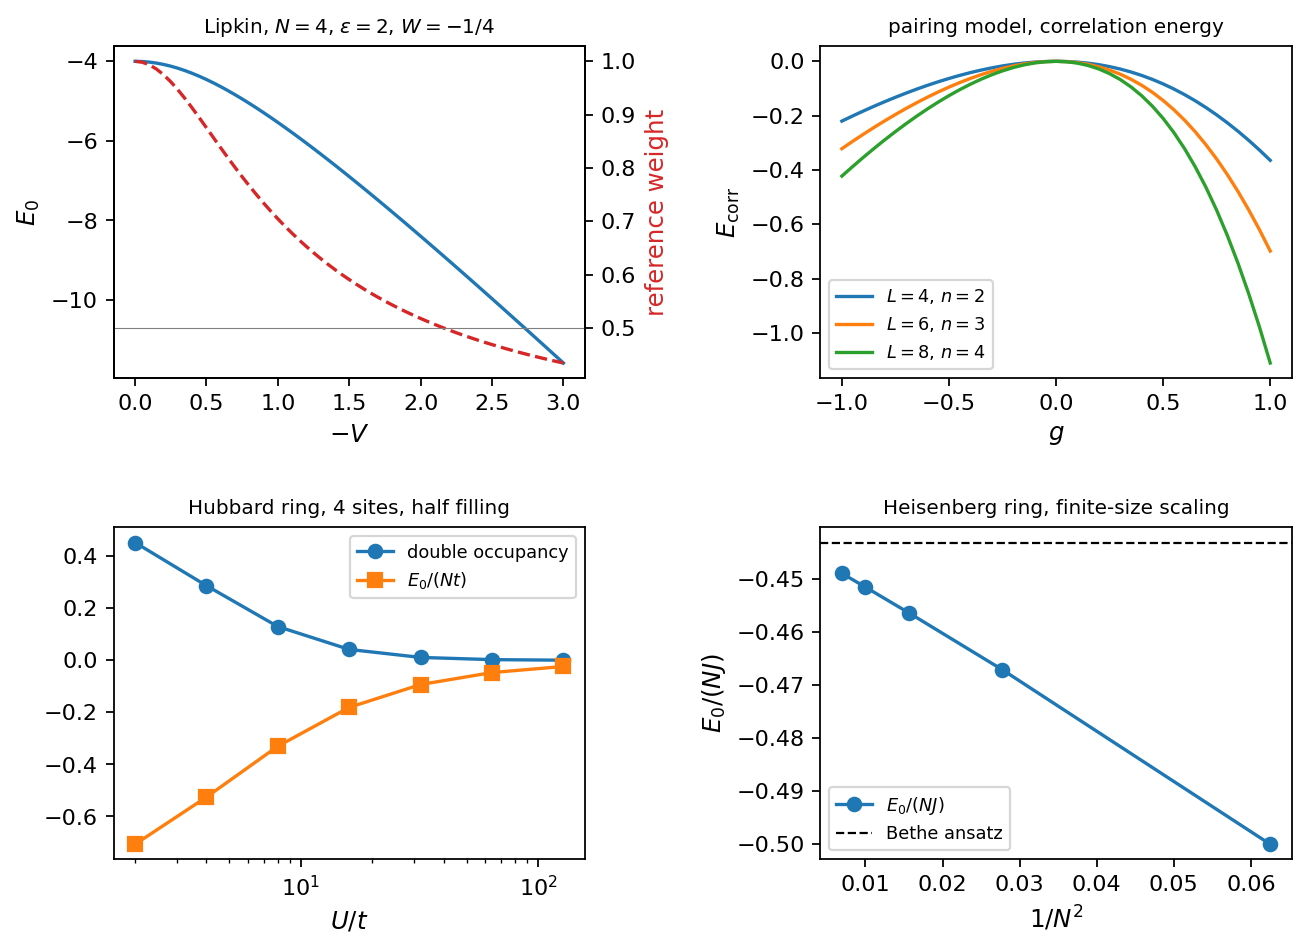

In [13]:
import runpy, time
from IPython.display import Image, display
t0 = time.time()
runpy.run_path(str(root / 'BookPrograms' / 'chapter3/fci.py'), run_name='__main__')
for png in sorted((root / 'BookFigures' / 'chapter3').glob('*.png')):
    if png.stat().st_mtime >= t0:
        display(Image(str(png)))


=== Lipkin model, N = 4, eps = 1, W = 0 (Table 3.lipkinhf)
  chi  E_spherical         E_HF  E_mf formula  lambda_min    E_exact  solution
 0.25    -2.000000    -2.000000     -2.000000      0.7500  -2.020726  spherical


 0.50    -2.000000    -2.000000     -2.000000      0.5000  -2.081666  spherical
 0.90    -2.000000    -2.000000     -2.000000      0.1000  -2.253886  spherical


 1.00    -2.000000    -2.000000     -2.000000      0.0000  -2.309401  critical
 1.50    -2.000000    -2.166667     -2.166666     -0.5000  -2.645751  deformed


 2.00    -2.000000    -2.500000     -2.500000     -1.0000  -3.055050  deformed
 2.50    -2.000000    -2.900000     -2.900000     -1.5000  -3.511885  deformed

=== Pairing model, L = 4, N = 4: the mean field does nothing (Table 3.pairinghf)
    g       E_ref        E_HF     E_exact iterations  max|f_ai|
 0.25  1.75000000  1.75000000  1.73045985          2    0.0e+00
 0.50  1.50000000  1.50000000  1.41677428          2    0.0e+00
 1.00  1.00000000  1.00000000  0.63554847          2    0.0e+00

=== Half-filled Hubbard ring, 4 sites: restricted vs unrestricted mean field (Table 3.hubbardhf)
 U/t     E_para      E_UHF    E_exact  m_stagger
   1  -3.000000  -3.285509  -3.340848     0.2853
   2  -2.000000  -2.661001  -2.828427     0.3279
   4   0.000000  -1.763298  -2.102748     0.4081
   8   4.000000  -0.968871  -1.320235     0.4708

=== Thouless' theorem: the rotated state is a single determinant
  ||exp(T)|c> - prod_i b_i^dagger|0>|| = 6.9e-18, <c|c'> = 1.000000
  ||exp(T)|c> - (1+T)|c>|| 

figure written to /home/claude/qcbook/doc/Book/BookFigures/chapter3/lipkin_hf.pdf


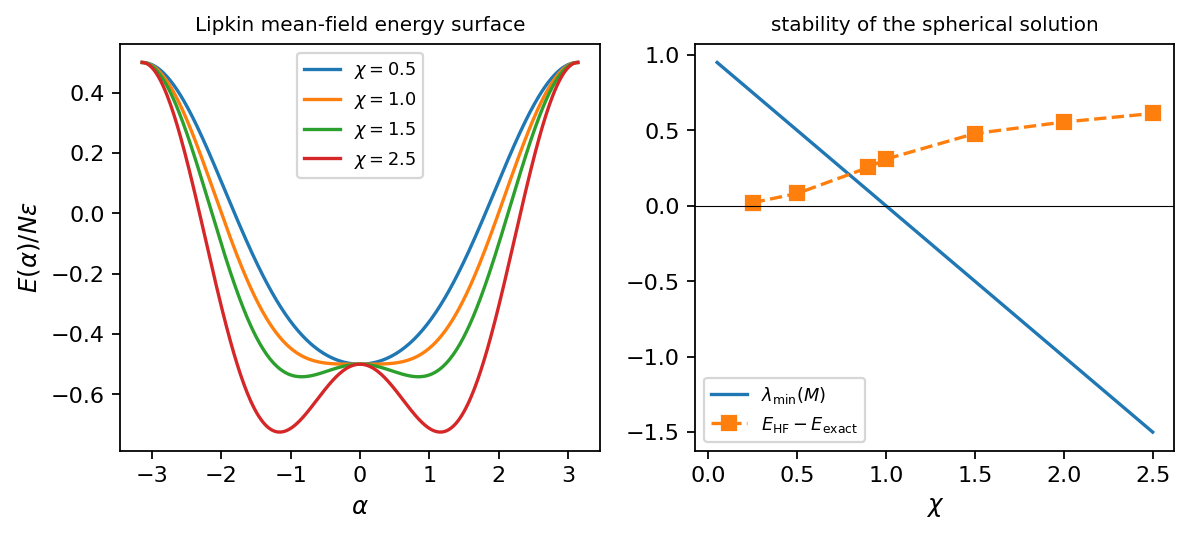

In [14]:
import runpy, time
from IPython.display import Image, display
t0 = time.time()
runpy.run_path(str(root / 'BookPrograms' / 'chapter3/hartreefock.py'), run_name='__main__')
for png in sorted((root / 'BookFigures' / 'chapter3').glob('*.png')):
    if png.stat().st_mtime >= t0:
        display(Image(str(png)))


=== BCH expansion, X = [[0,0.1],[0,0]], Y = [[0,0],[0.1,0]] (Table 3.bch)
  order 1: ||e^X e^Y - e^Z_n|| = 7.075e-03
  order 2: ||e^X e^Y - e^Z_n|| = 2.379e-04
  order 3: ||e^X e^Y - e^Z_n|| = 1.179e-05
  order 4: ||e^X e^Y - e^Z_n|| = 4.757e-07

=== Trotter splitting of exp(-i(X+Z)t), t = 1 (Table 3.trotter)
   N  first order  ratio  second order  ratio
   1    7.992e-01    ---     3.137e-01    ---
   2    3.624e-01   2.21     7.113e-02   4.41
   4    1.763e-01   2.06     1.727e-02   4.12
   8    8.751e-02   2.01     4.286e-03   4.03
  16    4.368e-02   2.00     1.070e-03   4.01
  32    2.183e-02   2.00     2.673e-04   4.00
  64    1.091e-02   2.00     6.680e-05   4.00

=== Heisenberg ring, 4 sites, even/odd bond splitting (Fig. 3.trotter)
  n =   1: first order 1.782e+00, second order 1.192e+00
  n =   2: first order 8.911e-01, second order 3.354e-01
  n =   4: first order 4.089e-01, second order 8.097e-02
  n =   8: first order 1.988e-01, second order 1.998e-02
  n =  16: first orde

figure written to /home/claude/qcbook/doc/Book/BookFigures/chapter3/trotter.pdf


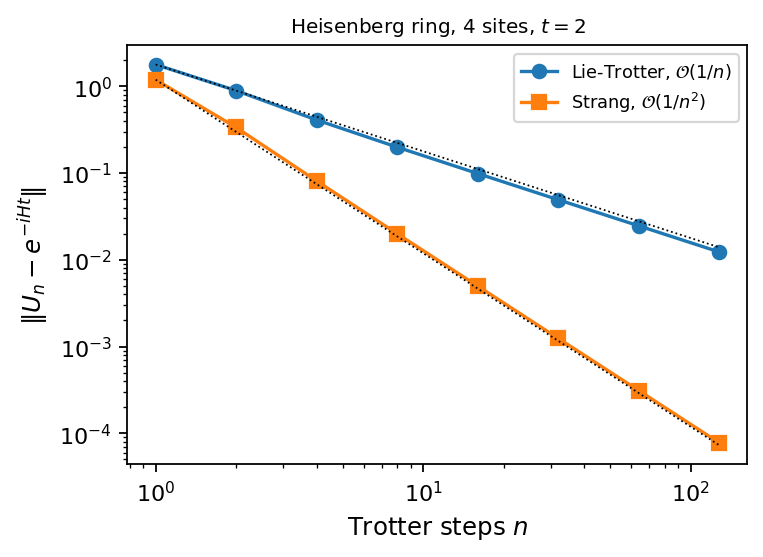

In [15]:
import runpy, time
from IPython.display import Image, display
t0 = time.time()
runpy.run_path(str(root / 'BookPrograms' / 'chapter3/trotter.py'), run_name='__main__')
for png in sorted((root / 'BookFigures' / 'chapter3').glob('*.png')):
    if png.stat().st_mtime >= t0:
        display(Image(str(png)))


=== CCD for the pairing model, L = 4, two pairs (Table 3.ccd)
    g    E_ref          MP2          CCD          FCI  CCD error  iter
 0.25  1.75000   1.73320261   1.73045621   1.73045985   -3.6e-06    13
 0.50  1.50000   1.43760684   1.41663766   1.41677428   -1.4e-04    18
 1.00  1.00000   0.78095238   0.63044275   0.63554847   -5.1e-03    26
 1.50  0.50000   0.05974026  -0.38416526  -0.34819051   -3.6e-02    30
 2.00  0.00000  -0.70833333  -1.60959440  -1.48965216   -1.2e-01    31

=== Unitary coupled cluster, g = 1: generator redundancy


  pairs            :   4 amplitudes, E(UCC) = 0.6369869810 (11 BFGS iterations)


  doubles          :  36 amplitudes, E(UCC) = 0.6369869810 (18 BFGS iterations)


  singles+doubles  :  52 amplitudes, E(UCC) = 0.6369869810 (19 BFGS iterations)

=== UCCD against CCD and FCI (Table 3.uccd)
    g          CCD         UCCD          FCI  CCD error  UCCD error
 0.25   1.73045621   1.73046012   1.73045985   -3.6e-06     2.8e-07


 0.50   1.41663766   1.41679562   1.41677428   -1.4e-04     2.1e-05
 1.00   0.63044275   0.63698698   0.63554847   -5.1e-03     1.4e-03


 1.50  -0.38416526  -0.33675149  -0.34819051   -3.6e-02     1.1e-02
 2.00  -1.60959440  -1.45347633  -1.48965216   -1.2e-01     3.6e-02

=== Trotterised UCCD, g = 1: re-optimised amplitudes at each n


  exact exponential: E = 0.6369869810, error 1.44e-03
  n = 1: E = 0.6369869810, error 1.44e-03


  n = 2: E = 0.6369869810, error 1.44e-03
  n = 4: E = 0.6369869810, error 1.44e-03


  n = 8: E = 0.6369869810, error 1.44e-03

=== Trotterised UCCD with the amplitudes frozen (Table 3.ucctrotter)
   n ||psi_n - psi||  ratio  energy error  ratio
   1        3.56e-03    ---      6.78e-05    ---
   2        1.14e-03   3.13      6.38e-06  10.63
   4        4.56e-04   2.50      9.37e-07   6.81
   8        2.11e-04   2.16      1.93e-07   4.85
  16        1.03e-04   2.04      4.57e-08   4.23
  32        5.14e-05   2.01      1.13e-08   4.06
  64        2.57e-05   2.00      2.81e-09   4.01


figure written to /home/claude/qcbook/doc/Book/BookFigures/chapter3/coupled_cluster.pdf


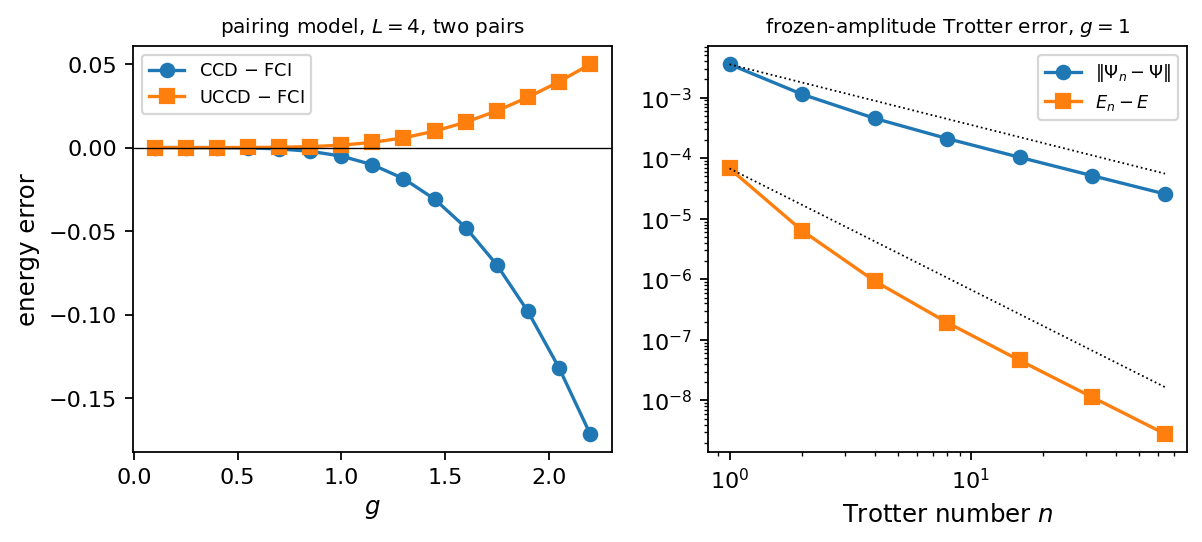

In [16]:
import runpy, time
from IPython.display import Image, display
t0 = time.time()
runpy.run_path(str(root / 'BookPrograms' / 'chapter3/coupledcluster.py'), run_name='__main__')
for png in sorted((root / 'BookFigures' / 'chapter3').glob('*.png')):
    if png.stat().st_mtime >= t0:
        display(Image(str(png)))
